# Evaluation: object-centric event logs from patient journeys

This notebook computes the numbers for Section 4 (Evaluation) of the paper *On the Creation of Object-Centric Event Logs from Patient Journeys*.

**What is evaluated.** Step 3 of the approach, the object-centric mapping, applied to the cohort log: 280 synthetic patients with myasthenia gravis, built by `pj2ocel` with `pj2ocel/mapping.yaml`. Steps 1 and 2 (extraction, temporal and semantic resolution) produced the export the log was built from. They are not evaluated here: that would need a ground truth for each journey, which the logs do not contain.

**Research questions.**

| | Question | Section |
|---|---|---|
| RQ1 | Feasibility: does the mapping produce valid OCEL 2.0 logs at cohort scale, and what becomes of every reported fact? | 1 |
| RQ2 | Requirements: how far does the log meet R1–R6? | 2 |
| RQ3 | Added value: what does the object-centric log keep that a case-centric log loses? | 3 |
| RQ4 | Use: which journey analyses does the log support? | 4 |

Section 5 measures limitations. Section 6 builds the paper's table and figures from the results and with PM4Py. The paper groups the results in three parts: the logs meet R1–R6 (table), the case-centric patient journey is still available without loss (PM4Py, patient as case), and object-centric process mining adds an analysis of comorbidity (PM4Py, OC-DFG). The notebook's principles P0–P10 (`pj2ocel/mapping-principles.md`) map to the paper's as follows: M1 = P1–P3, M2 = P6, M3 = P2 and P7 (perspectives), M4 = P8, M5 = P0.

**How every number is checked.** Each result for the paper is computed twice, by two independent routes: for example from the JSON file and from PM4Py's import of it, or by this notebook and by the build report that the mapping engine wrote. The function `report()` records a result only if all routes agree, and stops the notebook otherwise. Each section ends with a table of its results and the route each was checked against. Tables shown without `report()` are context; cite only reported results. Section 7 lists all results and writes them to `evaluation-results.json`.

**How to reproduce.** From the repository root:

```sh
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements-evaluation.txt
.venv/bin/jupyter nbconvert --to notebook --execute --inplace evaluation.ipynb
```

The inputs are pinned by their SHA-256 hash (section 0.1): the notebook stops if any of them has changed. Then, as a third check, `python3 evaluation_crosscheck.py` recomputes the headline results in plain Python, with no pandas, no PM4Py and no code shared with this notebook, and compares them with `evaluation-results.json`.

The notebook shows aggregate counts only, no patient-level records.

## 0. Setup

### 0.1 Inputs

The five files this evaluation reads, pinned by SHA-256. They are the versions committed in `6c835c8` ("Rebuild the cohort log with complete patients only"). If an input changes on purpose, update its hash here and re-run the whole notebook.

In [1]:
import copy
import hashlib
import json
import platform
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import pm4py
from IPython.display import display

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

INPUTS = {
    "journey log": ("logs/cohort-journey.ocel.json", "e9bdf9fdaab068d7d84e1174a9a8244db174fff3b47ea259a451ad72ebdb5daf"),
    "provenance log": ("logs/cohort-provenance.ocel.json", "ab33edfc2e975a1a90d330888e168a5c5987a09d5d8ec823503a3fb2460a3ecc"),
    "build report": ("logs/cohort-build-report.json", "2c99263ab9f34c45607fceabf6d21d89323bc24da8fea5be0398b66384c422b3"),
    "mapping": ("pj2ocel/mapping.yaml", "1b9d5c9813dc1215ba372a00e07398899b48992d0a69276cb84c312fddc20ed9"),
    "quality report": ("logs/cohort-quality.md", "58abcc52976843f9973c9a9b5cee0e95fc884e4fcea4eb4c26d116d164b77e12"),
}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


rows = []
for name, (path, pinned) in INPUTS.items():
    if not Path(path).is_file():
        raise FileNotFoundError(f"{path} not found. Run this notebook from the repository root.")
    rows.append({"Input": name, "File": path, "SHA-256": sha256(path), "As pinned": sha256(path) == pinned})
inputs_table = pd.DataFrame(rows).set_index("Input")
display(inputs_table)
assert inputs_table["As pinned"].all(), "An input differs from its pinned version (see the table above)."

ENVIRONMENT = {
    "Python": platform.python_version(),
    "PM4Py": pm4py.__version__,
    "pandas": pd.__version__,
    "NumPy": np.__version__,
}
display(ENVIRONMENT)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




,File,SHA-256,As pinned
Input,,,
journey log,logs/cohort-journey.ocel.json,e9bdf9fdaab068d7d84e1174a9a8244db174fff3b47ea259a451ad72ebdb5daf,True
provenance log,logs/cohort-provenance.ocel.json,ab33edfc2e975a1a90d330888e168a5c5987a09d5d8ec823503a3fb2460a3ecc,True
build report,logs/cohort-build-report.json,2c99263ab9f34c45607fceabf6d21d89323bc24da8fea5be0398b66384c422b3,True
mapping,pj2ocel/mapping.yaml,1b9d5c9813dc1215ba372a00e07398899b48992d0a69276cb84c312fddc20ed9,True
quality report,logs/cohort-quality.md,58abcc52976843f9973c9a9b5cee0e95fc884e4fcea4eb4c26d116d164b77e12,True


{'Python': '3.14.6', 'PM4Py': '2.7.23.12', 'pandas': '3.1.1', 'NumPy': '2.5.4'}

### 0.2 Recording results

`report(id, description, value, checks)` stores a result for the paper. `checks` maps a description of each second route to the value that route gives. The result is stored only if every route gives the same value (floats: equal to within 1e-9 before rounding); otherwise the notebook stops with both values. `show(prefix)` displays the results recorded so far whose id starts with `prefix`.

In [2]:
RESULTS = []


def _plain(v):
    """NumPy scalars to Python scalars, so results compare and serialise cleanly."""
    return v.item() if isinstance(v, np.generic) else v


def report(rid, description, value, checks, digits=None):
    value = _plain(value)
    assert checks, f"{rid}: a result needs at least one second route"
    for how, other in checks.items():
        other = _plain(other)
        if isinstance(value, float) or isinstance(other, float):
            agree = abs(float(value) - float(other)) <= 1e-9
        else:
            agree = value == other
        if not agree:
            raise AssertionError(f"{rid}: {value!r} (first route) != {other!r} ({how})")
    assert rid not in {r["id"] for r in RESULTS}, f"duplicate result id {rid}"
    if digits is not None:
        value = round(value, digits)
    RESULTS.append({"id": rid, "result": description, "value": value, "checked against": "; ".join(checks)})


def show(prefix):
    table = pd.DataFrame([r for r in RESULTS if r["id"].startswith(prefix)], dtype=object).set_index("id")
    display(table)

### 0.3 Load the logs

Each log is read twice: as plain JSON (the first route of most results) and by PM4Py (`pm4py.read_ocel2_json`, a second route). The build report is the mapping engine's own account of the build, including what it did not map and why.

In [3]:
J = json.loads(Path(INPUTS["journey log"][0]).read_text())        # journey log: occurrence time
PV = json.loads(Path(INPUTS["provenance log"][0]).read_text())    # provenance log: reporting time
BR = json.loads(Path(INPUTS["build report"][0]).read_text())      # build report of the mapping engine

ocel = pm4py.read_ocel2_json(INPUTS["journey log"][0])
prov_ocel = pm4py.read_ocel2_json(INPUTS["provenance log"][0])

display({"Mapping parameters the logs were built with (build report)": BR["params"]})

{'Mapping parameters the logs were built with (build report)': {'perspectives': ['Patient',
   'PatientCondition',
   'TreatmentCourse'],
  'min_lifecycle': 2,
  'event_statuses': ['occurred'],
  'time_anchor': 'lower',
  'initial_time': 'first_event',
  'relations': 'o2o',
  'evidence': 'attribute',
  'evidence_text': False,
  'change_types': 'events_on_target',
  'fact_object_types': 'per_type',
  'normalize_verbatim': True,
  'provenance_log': True}}

### 0.4 Base tables

Tables built once from the JSON files and used throughout. Identifiers follow the templates of `mapping.yaml`: a patient is `pat:<code>`, a fact (the carrier object of a reported clinical event) is `ce:<code>:<lineage>`, a journey is `pc:<code>:<condition>`, a treatment course `tc:<code>:<n>`, a milestone `ms:<code>:<type>`. A journey event is `e:<code>:<short id>`, with `:start`, `:end` or `:change` for the events of a period. Its assertion in the provenance log is `k:<code>:assert:<short id>`, or `k:<code>:rev:<short id>` for a revised fact.

- `EV`: one row per journey event, with its activity, time, patient, kind (*fact* or *milestone*), subject, and the fact it records.
- `E2O`: one row per event-to-object relationship of the journey log.
- `OBJ`: one row per journey object, with its type and patient.
- `FACTS`: one row per fact object of the journey log.
- `ASSERTIONS`: one row per `AssertFact` or `ReviseFact` event of the provenance log.

In [4]:
def attrs(item):
    """Attribute values of an OCEL item. An object can hold several values of one attribute over time: take the latest."""
    out = {}
    for a in sorted(item.get("attributes", []), key=lambda a: a.get("time", "")):
        out[a["name"]] = a["value"]
    return out


def related(item, qualifier):
    return [r["objectId"] for r in item.get("relationships", []) if r["qualifier"] == qualifier]


def patient_of_id(oid):
    """Patient code from an identifier: pat:S100 -> S100, ce:S100:... -> S100."""
    return oid.split(":")[1]


OBJ_TYPE = {o["id"]: o["type"] for o in J["objects"]}
OBJ_ATTR = {o["id"]: attrs(o) for o in J["objects"]}
PERSPECTIVES = BR["params"]["perspectives"]
FACT_TYPES = sorted({o["type"] for o in J["objects"] if o["id"].startswith("ce:")})
FACT_TYPE_SET = set(FACT_TYPES)

OBJ = pd.DataFrame(
    [{"object": o["id"], "type": o["type"], "patient": patient_of_id(o["id"])} for o in J["objects"]]
).set_index("object")

E2O = pd.DataFrame(
    [(e["id"], r["objectId"], r["qualifier"]) for e in J["events"] for r in e["relationships"]],
    columns=["event", "object", "qualifier"],
)

rows = []
for order, e in enumerate(J["events"]):
    a = attrs(e)
    concerns, subject, recorded_as = related(e, "concerns"), related(e, "subject"), related(e, "recorded_as")
    assert len(concerns) == 1 and len(subject) == 1 and len(recorded_as) <= 1, e["id"]
    kind = "milestone" if e["type"].startswith("Reach") else "fact"
    parts = e["id"].split(":")
    if recorded_as:
        fact = recorded_as[0]                  # a change event on a journey, recorded as this fact
    elif OBJ_TYPE[subject[0]] in FACT_TYPE_SET:
        fact = subject[0]
    else:
        fact = None                            # milestone event, or a change event without its own fact object
    rows.append({
        "event": e["id"],
        "order": order,                        # position in the file: PM4Py orders tied timestamps by it
        "activity": e["type"],
        "time": pd.Timestamp(e["time"]),
        "patient": patient_of_id(concerns[0]),
        "kind": kind,
        "subject": subject[0],
        "subject_type": OBJ_TYPE[subject[0]],
        "fact": fact,
        "short_id": parts[2] if kind == "fact" else None,
        "part": (parts[3] if len(parts) > 3 else "single") if kind == "fact" else None,
        "precision": a.get("precision"),
        "clinical_from": a.get("clinical_from"),
        "clinical_to": a.get("clinical_to"),
        "reported_at": pd.to_datetime(a["reported_at"], utc=True) if "reported_at" in a else pd.NaT,
        "end_derived_from": a.get("end_derived_from"),
        "end_precision": a.get("end_precision"),        # an end or change event is timed by its end
        "clinical_end_from": a.get("clinical_end_from"),
        "clinical_end_to": a.get("clinical_end_to"),
    })
EV = pd.DataFrame(rows).set_index("event")
FACT_EV = EV[EV["kind"].eq("fact")]

has_event = set(E2O["object"])
FACTS = pd.DataFrame([
    {
        "object": oid, "type": OBJ_TYPE[oid], "patient": patient_of_id(oid),
        "status": OBJ_ATTR[oid].get("status"),
        "clinical_from": OBJ_ATTR[oid].get("clinical_from"), "clinical_to": OBJ_ATTR[oid].get("clinical_to"),
        "has_event": oid in has_event,
    }
    for oid in OBJ.index[OBJ["type"].isin(FACT_TYPES)]
]).set_index("object")

PV_TYPE = {o["id"]: o["type"] for o in PV["objects"]}
SOURCE_TYPES = ["Message", "Document", "OnboardingAnswer", "OnboardingSession"]
rows = []
for e in PV["events"]:
    if e["type"] not in ("AssertFact", "ReviseFact"):
        continue
    _, code, verb, short_id = e["id"].split(":")
    subject = related(e, "subject")
    assert len(subject) == 1, e["id"]
    rows.append({
        "assertion": e["id"], "kind": e["type"], "patient": code, "short_id": short_id, "fact": subject[0],
        "time": pd.to_datetime(e["time"], utc=True),
        "time_raw": e["time"],
        "quotes": [s for s in related(e, "quotes") if PV_TYPE.get(s) in SOURCE_TYPES],
    })
ASSERTIONS = pd.DataFrame(rows).set_index("assertion")

display(pd.DataFrame({
    "Rows": {"EV (journey events)": len(EV), "E2O": len(E2O), "OBJ (journey objects)": len(OBJ),
             "FACTS (fact objects)": len(FACTS), "ASSERTIONS (provenance)": len(ASSERTIONS)},
}))
display({"Perspectives (build report)": PERSPECTIVES, "Fact object types": FACT_TYPES})

,Rows
EV (journey events),10364
E2O,30028
OBJ (journey objects),17706
FACTS (fact objects),13612
ASSERTIONS (provenance),13684


{'Perspectives (build report)': ['Patient',
  'PatientCondition',
  'TreatmentCourse'],
 'Fact object types': ['AdverseEvent',
  'Diagnosis',
  'DiagnosticProcedure',
  'DiseaseStatus',
  'HcpVisit',
  'Hospitalization',
  'InformationSearch',
  'Symptom',
  'Treatment']}

## 1. RQ1 Feasibility

### 1.1 Size of the logs

Counted in the JSON file; checked against PM4Py's import and against the build report. PM4Py reads fewer objects and relationships than the file holds: section 1.3 accounts for the difference exactly.

In [5]:
n_patients = int(OBJ["type"].eq("Patient").sum())
report("RQ1.patients", "Patients in the cohort log", n_patients,
       {"build report: cohort patients": BR["cohort"]["patients"],
        "distinct patients of the journey events": EV["patient"].nunique()})

exported = len(BR["patients"])
left_out = sum(1 for p in BR["patients"].values() if any(k.startswith("patient left out") for k in p["unmapped"]))
report("RQ1.patients_left_out", "Exported patients left out whole (no journey summary, P10)", exported - n_patients,
       {"build report: patients with 'patient left out'": left_out})
report("RQ1.patients_exported", "Patients in the export", exported,
       {"patients in the journey log plus patients labelled 'patient left out'": n_patients + left_out})
# The principles were developed on S01 and S31: neither is part of the cohort.
assert not {"S01", "S31"} & set(BR["patients"]), "a worked example is part of the cohort"

report("RQ1.events", "Events in the journey log", len(J["events"]),
       {"PM4Py import": len(ocel.events), "build report": BR["quality"]["size"]["events"]})
report("RQ1.fact_events", "Fact events (activities other than Reach*)", int(EV["kind"].eq("fact").sum()),
       {"events carrying reported_at (only fact events have it)": int(EV["reported_at"].notna().sum())})
report("RQ1.milestone_events", "Milestone events (Reach*)", int(EV["kind"].eq("milestone").sum()),
       {"build report: milestones minus milestones without event":
        BR["lifecycle"]["Milestone"]["objects"]
        - sum(sum(v for k, v in p["unmapped"].items() if k.startswith("no event: milestone")) for p in BR["patients"].values())})
report("RQ1.objects", "Objects in the journey log", len(J["objects"]), {"build report": BR["quality"]["size"]["objects"]})
report("RQ1.event_types", "Event types (activities)", len(J["eventTypes"]),
       {"PM4Py: distinct activities": ocel.events["ocel:activity"].nunique(),
        "build report": BR["quality"]["size"]["event types"]})
report("RQ1.object_types", "Object types", len(J["objectTypes"]),
       {"distinct types of the objects": OBJ["type"].nunique(), "build report": BR["quality"]["size"]["object types"]})
report("RQ1.e2o", "Event-to-object relationships (E2O)", len(E2O), {"build report": BR["quality"]["size"]["E2O"]})
n_o2o = sum(len(o.get("relationships", [])) for o in J["objects"])
report("RQ1.o2o", "Object-to-object relationships (O2O)", n_o2o, {"build report": BR["quality"]["size"]["O2O"]})
report("RQ1.provenance_events", "Events in the provenance log", len(PV["events"]), {"PM4Py import": len(prov_ocel.events)})
report("RQ1.provenance_objects", "Objects in the provenance log", len(PV["objects"]),
       {"PM4Py import (every provenance object has an event)": len(prov_ocel.objects)})

display(pd.DataFrame({
    "Journey log": Counter(e["type"] for e in J["events"]),
}).sort_values("Journey log", ascending=False).rename_axis("Event type"))
display(pd.DataFrame({
    "Provenance log": Counter(e["type"] for e in PV["events"]),
}).sort_values("Provenance log", ascending=False).rename_axis("Event type"))

,Journey log
Event type,
VisitHcp,2376
StartTreatment,1604
StartSymptom,1087
UndergoDiagnosticProcedure,968
ReceiveDiagnosis,644
ChangeTreatment,500
StartAdverseEvent,368
ReachDiagnosis,278
ReachSpecialistReferral,276


,Provenance log
Event type,
AssertFact,13681
SendMessage,12254
SubmitOnboardingAnswer,2795
UploadDocument,446
ReviseFact,3


### 1.2 Conformance to the OCEL 2.0 JSON format

`format_violations` checks the rules of the OCEL 2.0 JSON format: exactly the four top-level lists; unique type names and identifiers; every event and object of a declared type; every attribute declared for its type and holding a value of the declared type; an ISO 8601 time on every event and on every object attribute value; every relationship pointing to an existing object and carrying a qualifier. Times must match `YYYY-MM-DDThh:mm:ss[.fff](Z|±hh:mm)`.

**The checker is tested first.** For each of its rules, one fault is seeded into a copy of the journey log; the checker must report exactly that one violation and nothing else. Then both logs are checked.

In [6]:
ISO_8601 = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}(\.\d+)?(Z|[+-]\d{2}:\d{2})$")
FORMAT_RULES = [
    "top-level keys other than objectTypes, eventTypes, objects, events",
    "duplicate names in objectTypes", "duplicate names in eventTypes",
    "duplicate object ids", "duplicate event ids",
    "objects of an undeclared type", "events of an undeclared type",
    "object attributes not declared for the type", "event attributes not declared for the type",
    "object attribute values not of the declared type", "event attribute values not of the declared type",
    "object attribute values without an ISO 8601 time", "events without an ISO 8601 time",
    "object relationships to a missing object", "event relationships to a missing object",
    "object relationships without a qualifier", "event relationships without a qualifier",
]


def is_time(value):
    return isinstance(value, str) and bool(ISO_8601.match(value))


def fits(value, declared):
    if declared == "boolean":
        return isinstance(value, bool)
    if declared == "integer":
        return isinstance(value, int) and not isinstance(value, bool)
    if declared == "float":
        return isinstance(value, (int, float)) and not isinstance(value, bool)
    if declared == "time":
        return is_time(value)
    return isinstance(value, str)


def format_violations(log):
    v = Counter({rule: 0 for rule in FORMAT_RULES})
    v["top-level keys other than objectTypes, eventTypes, objects, events"] = len(
        set(log) ^ {"objectTypes", "eventTypes", "objects", "events"})
    declared = {}
    for kind in ("objectTypes", "eventTypes"):
        names = [t["name"] for t in log[kind]]
        v[f"duplicate names in {kind}"] = len(names) - len(set(names))
        declared[kind] = {t["name"]: {a["name"]: a["type"] for a in t.get("attributes", [])} for t in log[kind]}
    object_ids = {o["id"] for o in log["objects"]}
    v["duplicate object ids"] = len(log["objects"]) - len(object_ids)
    v["duplicate event ids"] = len(log["events"]) - len({e["id"] for e in log["events"]})
    for kind, items in (("objectTypes", log["objects"]), ("eventTypes", log["events"])):
        what = "object" if kind == "objectTypes" else "event"
        for item in items:
            if what == "event" and not is_time(item.get("time")):
                v["events without an ISO 8601 time"] += 1
            for r in item.get("relationships", []):
                v[f"{what} relationships to a missing object"] += r.get("objectId") not in object_ids
                v[f"{what} relationships without a qualifier"] += not isinstance(r.get("qualifier"), str)
            if item["type"] not in declared[kind]:
                v[f"{what}s of an undeclared type"] += 1
                continue
            types = declared[kind][item["type"]]
            for a in item.get("attributes", []):
                if a["name"] not in types:
                    v[f"{what} attributes not declared for the type"] += 1
                elif not fits(a["value"], types[a["name"]]):
                    v[f"{what} attribute values not of the declared type"] += 1
                if what == "object" and not is_time(a.get("time")):
                    v["object attribute values without an ISO 8601 time"] += 1
    assert set(v) == set(FORMAT_RULES), set(v) ^ set(FORMAT_RULES)
    return v


def first_with(items, key):
    return next(i for i in items if i.get(key))


def string_attr(log, kind, items):
    """The first item with an attribute declared as string, and that attribute's index."""
    declared = {t["name"]: {a["name"]: a["type"] for a in t.get("attributes", [])} for t in log[kind]}
    for item in items:
        for k, a in enumerate(item.get("attributes", [])):
            if declared[item["type"]].get(a["name"]) == "string":
                return item, k
    raise ValueError("no string attribute")


def seed(rule, log):
    """Insert one fault that violates `rule` into `log` (a copy)."""
    o, e = first_with(log["objects"], "relationships"), first_with(log["events"], "relationships")
    if rule.startswith("top-level"):
        log["extra"] = []
    elif rule == "duplicate names in objectTypes":
        log["objectTypes"].append(copy.deepcopy(log["objectTypes"][0]))
    elif rule == "duplicate names in eventTypes":
        log["eventTypes"].append(copy.deepcopy(log["eventTypes"][0]))
    elif rule == "duplicate object ids":
        log["objects"].append(copy.deepcopy(o))
    elif rule == "duplicate event ids":
        log["events"].append(copy.deepcopy(e))
    elif rule == "objects of an undeclared type":
        o["type"] = "UndeclaredType"
    elif rule == "events of an undeclared type":
        e["type"] = "UndeclaredType"
    elif rule == "object attributes not declared for the type":
        first_with(log["objects"], "attributes")["attributes"].append(
            {"name": "undeclared", "value": "x", "time": "2020-01-01T00:00:00Z"})
    elif rule == "event attributes not declared for the type":
        e.setdefault("attributes", []).append({"name": "undeclared", "value": "x"})
    elif rule == "object attribute values not of the declared type":
        item, k = string_attr(log, "objectTypes", log["objects"])
        item["attributes"][k]["value"] = 123
    elif rule == "event attribute values not of the declared type":
        item, k = string_attr(log, "eventTypes", log["events"])
        item["attributes"][k]["value"] = 123
    elif rule == "object attribute values without an ISO 8601 time":
        first_with(log["objects"], "attributes")["attributes"][0]["time"] = "2020-01-01"
    elif rule == "events without an ISO 8601 time":
        e["time"] = "2020-01-01"
    elif rule == "object relationships to a missing object":
        o["relationships"][0]["objectId"] = "missing"
    elif rule == "event relationships to a missing object":
        e["relationships"][0]["objectId"] = "missing"
    elif rule == "object relationships without a qualifier":
        del o["relationships"][0]["qualifier"]
    elif rule == "event relationships without a qualifier":
        del e["relationships"][0]["qualifier"]
    return log


self_test = []
for rule in FORMAT_RULES:
    found = format_violations(seed(rule, copy.deepcopy(J)))
    self_test.append({"Seeded fault": rule, "Detected by its rule": found[rule],
                      "Other violations": sum(found.values()) - found[rule]})
self_test = pd.DataFrame(self_test).set_index("Seeded fault")
display(self_test)
detected = int((self_test["Detected by its rule"].eq(1) & self_test["Other violations"].eq(0)).sum())

violations = pd.DataFrame({"journey log": format_violations(J), "provenance log": format_violations(PV)}).loc[FORMAT_RULES]
display(violations)

,Detected by its rule,Other violations
Seeded fault,,
"top-level keys other than objectTypes, eventTypes, objects, events",1,0
duplicate names in objectTypes,1,0
duplicate names in eventTypes,1,0
duplicate object ids,1,0
duplicate event ids,1,0
objects of an undeclared type,1,0
events of an undeclared type,1,0
object attributes not declared for the type,1,0
event attributes not declared for the type,1,0


,journey log,provenance log
"top-level keys other than objectTypes, eventTypes, objects, events",0,0
duplicate names in objectTypes,0,0
duplicate names in eventTypes,0,0
duplicate object ids,0,0
duplicate event ids,0,0
objects of an undeclared type,0,0
events of an undeclared type,0,0
object attributes not declared for the type,0,0
event attributes not declared for the type,0,0
object attribute values not of the declared type,0,0


The official OCEL 2.0 JSON schema would be a third, external check. Its published address (`https://www.ocel-standard.org/2.0/ocel20-schema-json.json`) returned *404 Not Found* on 2026-11-18. If you have a copy, save it as `ocel20-schema-json.json` in the repository root and install `jsonschema`: the next cell then validates both logs against it, and otherwise says that it skipped.

In [7]:
SCHEMA_PATH = Path("ocel20-schema-json.json")
try:
    import jsonschema
except ImportError:
    jsonschema = None
if SCHEMA_PATH.is_file() and jsonschema is not None:
    schema = json.loads(SCHEMA_PATH.read_text())
    for name, log in (("journey log", J), ("provenance log", PV)):
        errors = list(jsonschema.Draft7Validator(schema).iter_errors(log))
        print(f"{name}: {len(errors)} schema errors")
        assert not errors, errors[:3]
else:
    print("Skipped: the official schema file or the jsonschema package is not available.")

Skipped: the official schema file or the jsonschema package is not available.


In [8]:
report("RQ1.checker_self_test", "Format rules that detect exactly their seeded fault", detected,
       {"rules in the checker": len(FORMAT_RULES)})
report("RQ1.format_violations", "OCEL 2.0 JSON format violations, both logs", int(violations.values.sum()),
       {"events PM4Py failed to read, both logs (file events minus imported events)":
        (len(J["events"]) - len(ocel.events)) + (len(PV["events"]) - len(prov_ocel.events))})

### 1.3 What PM4Py reads, and what it leaves out

PM4Py imports every event, but leaves out three things the format allows. Each difference is computed from the JSON file and must equal the difference to PM4Py's import, item by item:

- objects without any event (a negated treatment, an undated visit, a milestone not reached): PM4Py keeps only objects referenced by an event;
- a second relationship between the same event and object (a `ChangeDiseaseStatus` relates to its journey as `subject` and as `in_journey`): PM4Py keeps one per pair;
- O2O relationships with an endpoint that has no event.

This matters for R4 (section 2.4): what did not happen is in the log, but a PM4Py analysis does not see it.

In [9]:
with_event = set(E2O["object"])
pm4py_objects = set(ocel.objects["ocel:oid"])
assert pm4py_objects == with_event, "PM4Py's objects are not exactly the objects that have an event"
report("RQ1.objects_without_event", "Journey objects without any event (left out by PM4Py)", len(OBJ) - len(with_event),
       {"build report: objects never referenced by an event": BR["quality"]["objects never referenced by an event"],
        "file objects minus PM4Py objects": len(J["objects"]) - len(ocel.objects)})

pairs = E2O.drop_duplicates(["event", "object"])
assert set(map(tuple, ocel.relations[["ocel:eid", "ocel:oid"]].values)) == set(map(tuple, pairs[["event", "object"]].values))
report("RQ1.e2o_second_qualifier", "E2O relationships repeating an (event, object) pair (merged by PM4Py)",
       len(E2O) - len(pairs), {"file E2O minus PM4Py relations": len(E2O) - len(ocel.relations)})

o2o = pd.DataFrame([(o["id"], r["objectId"], r["qualifier"]) for o in J["objects"] for r in o.get("relationships", [])],
                   columns=["source", "target", "qualifier"])
o2o_visible = o2o[o2o["source"].isin(with_event) & o2o["target"].isin(with_event)]
assert set(map(tuple, ocel.o2o[["ocel:oid", "ocel:oid_2", "ocel:qualifier"]].values)) == set(map(tuple, o2o_visible.values))
report("RQ1.o2o_not_in_pm4py", "O2O relationships with an endpoint without events (left out by PM4Py)",
       len(o2o) - len(o2o_visible), {"file O2O minus PM4Py O2O": len(o2o) - len(ocel.o2o)})

### 1.4 What becomes of every reported fact

Every fact the export reports has exactly one assertion in the provenance log (`AssertFact`, or `ReviseFact` for a revised fact). The table follows each of them into the journey log. A fact becomes an object that records it (P2) and, if it occurred at a resolved time, a start event (P1). There is one exception. A change of disease status that no relation points at becomes an event on its journey and needs no object of its own (P3). Both routes must account for every fact:

- **First route.** It starts from the journey log: the fact objects with their status, dates and events, plus the change events that have no fact object.
- **Second route.** It starts from the build report: the engine's count of each reason for not creating an event.

A start event is the event of a fact with no suffix or the suffix `:start`. End and change events are the `:end` and `:change` events of a period.

In [10]:
assert ASSERTIONS["fact"].is_unique, "a fact has more than one assertion"
fact_records = len(ASSERTIONS)

start_events = FACT_EV[FACT_EV["part"].isin(["single", "start"])]
facts_with_start = set(start_events["fact"].dropna())
pure_change = start_events[start_events["fact"].isna()]          # change events without a fact object
assert pure_change["activity"].eq("ChangeDiseaseStatus").all() and pure_change["subject_type"].eq("PatientCondition").all()

# Disclosure time of each fact: the time of its assertion in the provenance log.
# The engine's rule (mapping.yaml, `materialisable`): a start dated after the first 19 characters of the
# disclosure time, compared as strings, is "dated after it was reported".
disclosed = ASSERTIONS.set_index("fact")["time_raw"]
f = FACTS.copy()
f["disclosed"] = f.index.map(disclosed)
f["category"] = None
f.loc[f["status"].eq("negated"), "category"] = "object only: negated"
f.loc[f["status"].eq("intended"), "category"] = "object only: intended"
occurred = f["status"].eq("occurred")
f.loc[occurred & f["clinical_from"].isna(), "category"] = "object only: start not resolved in time"
after = occurred & f["clinical_from"].notna() & (f["clinical_from"].fillna("") > f["disclosed"].str[:19])
f.loc[after, "category"] = "object only: dated after it was reported"
expected_event = occurred & f["clinical_from"].notna() & ~after
f.loc[expected_event, "category"] = "object and start event"
assert f["category"].notna().all(), f[f["category"].isna()]["status"].value_counts()
# P1 holds exactly: the facts with a start event are the facts that occurred, are dated, and are not dated after
# their report. This compares the rule (from the facts' attributes) with the events the log actually has.
assert set(f.index[expected_event]) == facts_with_start

categories = f["category"].value_counts()
categories["event only: change of disease status on its journey"] = len(pure_change)
order = ["object and start event", "event only: change of disease status on its journey",
         "object only: negated", "object only: intended",
         "object only: start not resolved in time", "object only: dated after it was reported"]
categories = categories.reindex(order)
with_end_only = f[f["category"].eq("object only: start not resolved in time") & f["has_event"]]
fact_table = pd.DataFrame({"Facts": categories, "Share (%)": (100 * categories / categories.sum()).round(1)})
display(fact_table)
display({"Facts without a resolved start that still have a dated end event": len(with_end_only)})


def unmapped_total(label):
    return sum(p["unmapped"].get(label, 0) for p in BR["patients"].values())


report("RQ1.fact_records", "Facts reported (assertions in the provenance log)", fact_records,
       {"fact objects plus change events without a fact object": len(FACTS) + len(pure_change),
        "sum of the categories above": int(categories.sum())})
report("RQ1.facts_with_event", "Facts with a start event (object and event)", int(categories["object and start event"]),
       {"start events of the journey log minus change events without a fact object": len(start_events) - len(pure_change)})
report("RQ1.facts_change_only", "Facts that are a change event on their journey, without own object",
       int(categories["event only: change of disease status on its journey"]),
       {"provenance facts that are not journey objects": int((~ASSERTIONS["fact"].isin(OBJ.index)).sum())})
report("RQ1.facts_negated", "Facts negated (object, no event)", int(categories["object only: negated"]),
       {"build report: no event: status negated": unmapped_total("no event: status negated")})
report("RQ1.facts_intended", "Facts intended (object, no event)", int(categories["object only: intended"]),
       {"build report: no event: status intended": unmapped_total("no event: status intended")})
report("RQ1.facts_unresolved", "Facts that occurred without a resolved start (object, no start event)",
       int(categories["object only: start not resolved in time"]),
       {"build report: no event: temporally unresolved": unmapped_total("no event: temporally unresolved")})
report("RQ1.facts_after_report", "Facts dated after they were reported (object, no event)",
       int(categories["object only: dated after it was reported"]),
       {"build report: no event: dated after it was reported": unmapped_total("no event: dated after it was reported")})
report("RQ1.facts_without_event_pct", "Facts kept as objects without a start event (%)",
       100 * categories.filter(like="object only").sum() / fact_records,
       {"100 x (facts - start events) / facts": 100 * (fact_records - len(start_events)) / fact_records}, digits=1)

,Facts,Share (%)
category,,
object and start event,7274,53.2
event only: change of disease status on its journey,72,0.5
object only: negated,5024,36.7
object only: intended,353,2.6
object only: start not resolved in time,956,7.0
object only: dated after it was reported,5,0.0


{'Facts without a resolved start that still have a dated end event': 34}

Milestones are the journey summary. A milestone is an object; it has a `Reach*` event only if it was reached and dated.

In [11]:
MS = pd.DataFrame([
    {"milestone": o["id"], "patient": patient_of_id(o["id"]), "type": OBJ_ATTR[o["id"]]["milestone_type"],
     "presence": OBJ_ATTR[o["id"]].get("presence")}
    for o in J["objects"] if o["type"] == "Milestone"
]).set_index("milestone")
MS["event_time"] = MS.index.map(EV[EV["kind"].eq("milestone")].reset_index().set_index("subject")["time"])
assert not MS.duplicated(["patient", "type"]).any()
ms_table = pd.DataFrame({
    "Milestones": {
        "reached, dated (event)": int(MS["event_time"].notna().sum()),
        "reached, undated (object only)": int((MS["presence"].eq("reached") & MS["event_time"].isna()).sum()),
        "not reached (object only)": int(MS["presence"].eq("not_reached").sum()),
    }
})
assert ms_table["Milestones"].sum() == len(MS)
display(ms_table)
report("RQ1.milestones", "Milestone objects", len(MS), {"build report lifecycle": BR["lifecycle"]["Milestone"]["objects"]})
report("RQ1.milestones_undated", "Milestones reached but undated (object, no event)",
       int(ms_table.loc["reached, undated (object only)", "Milestones"]),
       {"build report: no event: milestone reached, undated": unmapped_total("no event: milestone reached, undated")})
show("RQ1.")

,Milestones
"reached, dated (event)",2000
"reached, undated (object only)",157
not reached (object only),110


,result,value,checked against
id,,,
RQ1.patients,Patients in the cohort log,280,build report: cohort patients; distinct patients of the journey events
RQ1.patients_left_out,"Exported patients left out whole (no journey summary, P10)",4,build report: patients with 'patient left out'
RQ1.patients_exported,Patients in the export,284,patients in the journey log plus patients labelled 'patient left out'
RQ1.events,Events in the journey log,10364,PM4Py import; build report
RQ1.fact_events,Fact events (activities other than Reach*),8364,events carrying reported_at (only fact events have it)
RQ1.milestone_events,Milestone events (Reach*),2000,build report: milestones minus milestones without event
RQ1.objects,Objects in the journey log,17706,build report
RQ1.event_types,Event types (activities),30,PM4Py: distinct activities; build report
RQ1.object_types,Object types,13,distinct types of the objects; build report


## 2. RQ2 Requirements

### 2.1 R1 Traceable evidence

A fact event is **traceable** if it leads to at least one source (a message, a document, or an onboarding answer or session) that exists in the provenance log. Two independent routes:

1. **Through the provenance log.** Join the event to its fact's assertion by identifier (`e:<code>:<short id>` to `k:<code>:assert:<short id>` or `k:<code>:rev:<short id>`, as defined in `mapping.yaml`). Then check that the assertion quotes a source object.
2. **Through the journey log.** Read the evidence references on the event's fact object, or on the event itself for a change event without a fact object (`message:<id>`, `document:<id>`, `onboarding:<id>`). Resolve each to its source object in the provenance log (`msg:<code>:<id>`, `doc:<code>:<id>`, `onbsession:<code>:<id>`; the templates of `quoted_source` in `mapping.yaml`).

Milestone events are left out: the export gives only how many facts support a milestone, not which ones (section 5).

In [12]:
assertion_by_short = ASSERTIONS.reset_index().set_index(["patient", "short_id"])
assert assertion_by_short.index.is_unique
joined = FACT_EV.join(assertion_by_short[["assertion", "kind", "fact", "time", "quotes"]]
                      .rename(columns={"kind": "kind_assertion", "fact": "fact_assertion", "time": "time_assertion"}),
                      on=["patient", "short_id"])
assert joined["assertion"].notna().all(), "a fact event has no assertion"
# The event and its assertion name the same fact (where the event has a fact object).
has_fact = joined["fact"].notna()
assert (joined.loc[has_fact, "fact"] == joined.loc[has_fact, "fact_assertion"]).all()
route_provenance = joined["quotes"].map(len).gt(0)

REF_TEMPLATE = {"message": "msg:{p}:{id}", "document": "doc:{p}:{id}", "onboarding": "onbsession:{p}:{id}"}
event_refs = {e["id"]: attrs(e).get("evidence_refs") for e in J["events"]}


def resolved_refs(event_id, row):
    refs = OBJ_ATTR[row["fact"]].get("evidence_refs") if pd.notna(row["fact"]) else event_refs[event_id]
    out = []
    for ref in (refs or "").split("; "):
        m = re.match(r"^(message|document|onboarding):([0-9a-f]{8})", ref)
        if m:
            sid = REF_TEMPLATE[m.group(1)].format(p=row["patient"], id=m.group(2))
            if sid in PV_TYPE:
                out.append(sid)
    return out


route_journey = pd.Series({eid: bool(resolved_refs(eid, row)) for eid, row in FACT_EV.iterrows()})
n_fact_events = len(FACT_EV)
report("RQ2.R1.traceable_events", "Fact events traceable to a source", int(route_provenance.sum()),
       {"evidence references resolved in the provenance log": int(route_journey.sum())})
report("RQ2.R1.traceable_events_pct", "Fact events traceable to a source (%)", 100 * route_provenance.mean(),
       {"evidence references resolved (%)": 100 * route_journey.mean()}, digits=1)

# Which kinds of source the facts quote.
quoted_types = ASSERTIONS["quotes"].map(lambda q: sorted({PV_TYPE[s] for s in q}))
sources = pd.Series(Counter(t for ts in quoted_types for t in ts)).reindex(SOURCE_TYPES, fill_value=0)
display(pd.DataFrame({"Facts quoting it": sources,
                      "Source objects in the provenance log": pd.Series(Counter(PV_TYPE.values())).reindex(SOURCE_TYPES, fill_value=0)}))
report("RQ2.R1.documents_uploaded", "Documents uploaded", int(sum(e["type"] == "UploadDocument" for e in PV["events"])),
       {"Document objects in the provenance log": sum(t == "Document" for t in PV_TYPE.values())})
report("RQ2.R1.facts_from_documents", "Facts quoting a document", int(sources["Document"]),
       {"fact objects whose source channel is a document":
        sum(1 for oid in FACTS.index if OBJ_ATTR[oid].get("source_channel") == "document")})
report("RQ2.R1.revised_facts", "Facts revised after their first report (ReviseFact)", int(ASSERTIONS["kind"].eq("ReviseFact").sum()),
       {"build report: provenance: first assertion of a revised fact has no time":
        unmapped_total("provenance: first assertion of a revised fact has no time")})

,Facts quoting it,Source objects in the provenance log
Message,9073,12254
Document,0,446
OnboardingAnswer,0,2795
OnboardingSession,6217,814


**Reporting delay.** The time from when a fact event happened to when it was reported. This is why the log has two clocks (P0). First route: the event's `reported_at` attribute in the journey log. Second route: the time of its assertion in the provenance log.

In [13]:
DAYS_PER_YEAR = 365.25
delay = (joined["reported_at"] - joined["time"]).dt.days / DAYS_PER_YEAR
delay_prov = (joined["time_assertion"] - joined["time"]).dt.days / DAYS_PER_YEAR
display(pd.DataFrame({"journey log (reported_at)": delay.describe(), "provenance log (assertion time)": delay_prov.describe()}).round(2))
report("RQ2.R1.delay_median_years", "Reporting delay of fact events, median (years)", delay.median(),
       {"provenance assertion time": delay_prov.median()}, digits=1)
report("RQ2.R1.delay_q1_years", "Reporting delay, first quartile (years)", delay.quantile(0.25),
       {"provenance assertion time": delay_prov.quantile(0.25)}, digits=1)
report("RQ2.R1.delay_q3_years", "Reporting delay, third quartile (years)", delay.quantile(0.75),
       {"provenance assertion time": delay_prov.quantile(0.75)}, digits=1)
report("RQ2.R1.delay_over_1y_pct", "Fact events reported more than a year after they happened (%)", 100 * (delay > 1).mean(),
       {"provenance assertion time": 100 * (delay_prov > 1).mean()}, digits=1)
report("RQ2.R1.delay_over_5y_pct", "Fact events reported more than five years after they happened (%)", 100 * (delay > 5).mean(),
       {"provenance assertion time": 100 * (delay_prov > 5).mean()}, digits=1)
report("RQ2.R1.delay_negative", "Fact events timed after their report", int((delay < 0).sum()),
       {"provenance assertion time": int((delay_prov < 0).sum())})
display(joined[delay < 0].groupby(["activity", "end_derived_from"], dropna=False).size().rename("Fact events timed after their report"))
show("RQ2.R1.")

,journey log (reported_at),provenance log (assertion time)
count,8364.00,8364.00
mean,4.75,4.75
std,5.82,5.82
min,-0.70,-0.70
25%,0.90,0.90
50%,3.22,3.22
75%,7.19,7.19
max,66.02,66.02


activity         end_derived_from
ChangeTreatment  clinical end        5
EndSymptom       clinical end        1
EndTreatment     clinical end        1
Name: Fact events timed after their report, dtype: int64

,result,value,checked against
id,,,
RQ2.R1.traceable_events,Fact events traceable to a source,8364,evidence references resolved in the provenance log
RQ2.R1.traceable_events_pct,Fact events traceable to a source (%),100.0,evidence references resolved (%)
RQ2.R1.documents_uploaded,Documents uploaded,446,Document objects in the provenance log
RQ2.R1.facts_from_documents,Facts quoting a document,0,fact objects whose source channel is a document
RQ2.R1.revised_facts,Facts revised after their first report (ReviseFact),3,build report: provenance: first assertion of a revised fact has no time
RQ2.R1.delay_median_years,"Reporting delay of fact events, median (years)",3.2,provenance assertion time
RQ2.R1.delay_q1_years,"Reporting delay, first quartile (years)",0.9,provenance assertion time
RQ2.R1.delay_q3_years,"Reporting delay, third quartile (years)",7.2,provenance assertion time
RQ2.R1.delay_over_1y_pct,Fact events reported more than a year after they happened (%),73.5,provenance assertion time


### 2.2 R2 Uncertain time

How precisely event times are known, and what that does to ordering. An end or change event is timed by the end of its period: its precision is `end_precision` and its date range `clinical_end_from` to `clinical_end_to` (its `precision` and `clinical_from` describe the start). A start, single or milestone event uses `precision` and `clinical_from` to `clinical_to`. An event known only to the month is placed on the first day of the month (`time_anchor = lower`), so events of one object often share a timestamp. PM4Py then orders them by their position in the file, which is arbitrary. Facts whose start has no resolved time are kept as objects (`RQ1.facts_unresolved`).

In [14]:
PRECISION_ORDER = ["day", "week", "month", "quarter", "year", "before", "missing"]
is_end = EV["part"].isin(["end", "change"])
prec = EV["precision"].where(~is_end, EV["end_precision"]).fillna("missing")
pm_events = ocel.events.set_index("ocel:eid").loc[EV.index]
pm_is_end = pm_events.index.str.endswith((":end", ":change"))
prec_pm = pm_events["precision"].where(~pm_is_end, pm_events["end_precision"]).fillna("missing")
has_range = (EV["clinical_from"].notna() & EV["clinical_to"].notna()).where(
    ~is_end, EV["clinical_end_from"].notna() & EV["clinical_end_to"].notna())
has_range_pm = (pm_events["clinical_from"].notna() & pm_events["clinical_to"].notna()).where(
    ~pm_is_end, pm_events["clinical_end_from"].notna() & pm_events["clinical_end_to"].notna())
table = pd.crosstab(prec, EV["kind"]).reindex(PRECISION_ORDER).dropna(how="all").fillna(0).astype(int)
table["all"] = table.sum(axis=1)
table["all (%)"] = (100 * table["all"] / table["all"].sum()).round(1)
display(table.rename_axis("Date precision"))

report("RQ2.R2.day_precision_pct", "Events dated to the day (%)", 100 * prec.eq("day").mean(),
       {"PM4Py events table": 100 * prec_pm.eq("day").mean()}, digits=1)
report("RQ2.R2.month_precision_pct", "Events dated to the month (%)", 100 * prec.eq("month").mean(),
       {"PM4Py events table": 100 * prec_pm.eq("month").mean()}, digits=1)
report("RQ2.R2.events_with_range_pct", "Events that keep the date range and precision of their time (%)",
       100 * (has_range & prec.ne("missing")).mean(),
       {"PM4Py events table": 100 * (has_range_pm & prec_pm.ne("missing")).mean()}, digits=1)
report("RQ2.R2.coarser_than_day_pct", "Events dated more coarsely than to the day, or without precision (%)",
       100 * prec.ne("day").mean(), {"PM4Py events table": 100 * prec_pm.ne("day").mean()}, digits=1)
display(EV["end_derived_from"].value_counts(dropna=False).rename("Events").rename_axis("end_derived_from"))
report("RQ2.R2.end_from_clinical_end", "End and change events dated from an end date in the sources",
       int(EV["end_derived_from"].eq("clinical end").sum()),
       {"events with suffix :end or :change": int(FACT_EV["part"].isin(["end", "change"]).sum()),
        "PM4Py events table": int(ocel.events["end_derived_from"].eq("clinical end").sum())})
report("RQ2.R2.end_from_duration", "End events dated from a stated duration (start + duration)",
       int(EV["end_derived_from"].eq("start + reported duration").sum()),
       {"end and change events minus those dated from an end date":
        int(FACT_EV["part"].isin(["end", "change"]).sum()) - int(EV["end_derived_from"].eq("clinical end").sum())})

kind,fact,milestone,all,all (%)
Date precision,,,,
day,1800,406,2206,21.3
week,467,74,541,5.2
month,5010,1273,6283,60.6
quarter,1025,224,1249,12.1
year,62,23,85,0.8


end_derived_from
NaN             9346
clinical end    1018
Name: Events, dtype: int64

**Tied timestamps in the perspectives.** For each perspective (P2), the directly-follows pairs of fact events: two consecutive events of one object. A pair is *tied* if both events have the same timestamp. First route: the JSON file, ordered by time and then by position in the file. Second route: PM4Py's relations table, in the same order.

In [15]:
QUALIFIERS = {"Patient": ["concerns"], "PatientCondition": ["subject", "in_journey"], "TreatmentCourse": ["in_course"]}


def df_pairs_raw(object_type, events=FACT_EV):
    rel = E2O[E2O["qualifier"].isin(QUALIFIERS[object_type]) & E2O["event"].isin(events.index)]
    rel = rel[rel["object"].map(OBJ_TYPE).eq(object_type)].drop_duplicates(["event", "object"])
    rel = rel.join(EV[["time", "order", "activity"]], on="event").sort_values(["object", "time", "order"])
    nxt = rel.groupby("object").shift(-1)
    pairs = pd.DataFrame({"object": rel["object"], "a": rel["activity"], "b": nxt["activity"],
                          "t_a": rel["time"], "t_b": nxt["time"]}).dropna(subset=["b"])
    return pairs


def df_pairs_pm4py(object_type, activities):
    rel = ocel.relations[ocel.relations["ocel:type"].eq(object_type) & ocel.relations["ocel:activity"].isin(activities)]
    order = pd.Series(range(len(ocel.events)), index=ocel.events["ocel:eid"])
    rel = rel.assign(order=rel["ocel:eid"].map(order)).sort_values(["ocel:oid", "ocel:timestamp", "order"])
    nxt = rel.groupby("ocel:oid").shift(-1)
    return pd.DataFrame({"object": rel["ocel:oid"], "a": rel["ocel:activity"], "b": nxt["ocel:activity"],
                         "t_a": rel["ocel:timestamp"], "t_b": nxt["ocel:timestamp"]}).dropna(subset=["b"])


FACT_ACTIVITIES = sorted(FACT_EV["activity"].unique())
rows = []
for ot in PERSPECTIVES:
    raw_pairs, pm_pairs = df_pairs_raw(ot), df_pairs_pm4py(ot, FACT_ACTIVITIES)
    tied, tied_pm = raw_pairs["t_a"].eq(raw_pairs["t_b"]), pm_pairs["t_a"].eq(pm_pairs["t_b"])
    report(f"RQ2.R2.tied_pairs_{ot}_pct", f"Directly-follows pairs of fact events with tied timestamps, {ot} (%)",
           100 * tied.mean(), {"PM4Py relations": 100 * tied_pm.mean()}, digits=1)
    rows.append({"Perspective": ot, "Directly-follows pairs": len(raw_pairs), "Tied (%)": round(100 * tied.mean(), 1)})
display(pd.DataFrame(rows).set_index("Perspective"))
show("RQ2.R2.")

,Directly-follows pairs,Tied (%)
Perspective,,
Patient,8084,31.0
PatientCondition,4535,30.8
TreatmentCourse,1337,29.9


,result,value,checked against
id,,,
RQ2.R2.day_precision_pct,Events dated to the day (%),21.3,PM4Py events table
RQ2.R2.month_precision_pct,Events dated to the month (%),60.6,PM4Py events table
RQ2.R2.events_with_range_pct,Events that keep the date range and precision of their time (%),100.0,PM4Py events table
RQ2.R2.coarser_than_day_pct,"Events dated more coarsely than to the day, or without precision (%)",78.7,PM4Py events table
RQ2.R2.end_from_clinical_end,End and change events dated from an end date in the sources,1018,events with suffix :end or :change; PM4Py events table
RQ2.R2.end_from_duration,End events dated from a stated duration (start + duration),0,end and change events minus those dated from an end date
RQ2.R2.tied_pairs_Patient_pct,"Directly-follows pairs of fact events with tied timestamps, Patient (%)",31.0,PM4Py relations
RQ2.R2.tied_pairs_PatientCondition_pct,"Directly-follows pairs of fact events with tied timestamps, PatientCondition (%)",30.8,PM4Py relations
RQ2.R2.tied_pairs_TreatmentCourse_pct,"Directly-follows pairs of fact events with tied timestamps, TreatmentCourse (%)",29.9,PM4Py relations


### 2.3 R3 Normalized terminology

A term is two attributes on the fact (P8): the normalised code and the patient's own words. The table counts fact events whose fact type has a term. A code is *specific* if it is a vocabulary code other than a catch-all. A *catch-all* code is one matching `CATCH_ALL` (such as `treatments.other`); the cell lists every code that matches it, and every code that contains "other" but does not match, so the pattern can be checked by eye. *Words kept*: the fact also has the patient's words (`*_verbatim`). *Shared*: a specific code that also occurs in another patient's journey, which is what makes patients comparable. First route: the JSON file. Second route: PM4Py's objects table, joined to the events through PM4Py's relations.

In [16]:
TERM = {
    "Treatment": ("treatment_name", "treatment_verbatim"),
    "Symptom": ("symptom_name", "symptom_verbatim"),
    "Diagnosis": ("condition_name", "condition_verbatim"),
    "DiagnosticProcedure": ("test_name", "test_verbatim"),
    "AdverseEvent": ("experience", "experience_verbatim"),
    "HcpVisit": ("hcp_specialty", "hcp_specialty_verbatim"),
}
declared_obj = {t["name"]: {a["name"] for a in t["attributes"]} for t in J["objectTypes"]}
assert all({code, words} <= declared_obj[t] for t, (code, words) in TERM.items())
CATCH_ALL = re.compile(r"\.other(_[a-z0-9_]+)?$")


def coding(code):
    if not isinstance(code, str) or code == "":
        return "no code"
    return "catch-all" if CATCH_ALL.search(code) else "specific"


def term_table(subjects, attr_of):
    """subjects: Series event -> fact object; attr_of(fact, name) -> value."""
    rows = []
    for event, fact in subjects.items():
        ftype = OBJ_TYPE[fact]
        if ftype not in TERM:
            continue
        code_attr, words_attr = TERM[ftype]
        code, words = attr_of(fact, code_attr), attr_of(fact, words_attr)
        rows.append({"event": event, "type": ftype, "patient": patient_of_id(fact), "code": code,
                     "coding": coding(code), "words kept": isinstance(words, str) and words.strip() != ""})
    t = pd.DataFrame(rows)
    per_code = t[t["coding"].eq("specific")].groupby("code")["patient"].nunique()
    t["shared"] = t["coding"].eq("specific") & t["code"].map(per_code).gt(1)
    return t


subjects_raw = FACT_EV["fact"].dropna()
terms = term_table(subjects_raw, lambda fact, name: OBJ_ATTR[fact].get(name))

pm_objects = ocel.objects.set_index("ocel:oid")
pm_subjects = ocel.relations[ocel.relations["ocel:qualifier"].eq("subject")].set_index("ocel:eid")["ocel:oid"]
pm_recorded = ocel.relations[ocel.relations["ocel:qualifier"].eq("recorded_as")].set_index("ocel:eid")["ocel:oid"]
pm_fact = pm_subjects.where(pm_subjects.map(lambda o: o.startswith("ce:")))
pm_fact.update(pm_recorded)
pm_fact = pm_fact.dropna()


def pm_attr(fact, name):
    v = pm_objects.at[fact, name] if name in pm_objects.columns else None
    return None if (v is None or (isinstance(v, float) and np.isnan(v))) else v


terms_pm = term_table(pm_fact, pm_attr)

table = pd.crosstab(terms["type"], terms["coding"], margins=True, margins_name="all").reindex(
    columns=["specific", "catch-all", "no code", "all"], fill_value=0)
table["Specific (%)"] = (100 * table["specific"] / table["all"]).round(1)
table["Words kept (%)"] = (100 * terms.groupby("type")["words kept"].mean()).reindex(table.index).round(1)
table.loc["all", "Words kept (%)"] = round(100 * terms["words kept"].mean(), 1)
table["Shared (%)"] = (100 * terms.groupby("type")["shared"].mean()).reindex(table.index).round(1)
table.loc["all", "Shared (%)"] = round(100 * terms["shared"].mean(), 1)
display(table)

all_codes = pd.Series(terms["code"].dropna().unique())
display({"Codes matching CATCH_ALL": sorted(all_codes[all_codes.map(lambda c: bool(CATCH_ALL.search(c)))]),
         "Codes containing 'other' that do not match": sorted(all_codes[all_codes.str.contains("other")
                                                                         & ~all_codes.map(lambda c: bool(CATCH_ALL.search(c)))])})

report("RQ2.R3.coded_events", "Fact events whose fact type has a term", len(terms), {"PM4Py": len(terms_pm)})
report("RQ2.R3.specific_pct", "Fact events with a specific code (%)", 100 * terms["coding"].eq("specific").mean(),
       {"PM4Py": 100 * terms_pm["coding"].eq("specific").mean()}, digits=1)
report("RQ2.R3.catch_all_pct", "Fact events with a catch-all code (%)", 100 * terms["coding"].eq("catch-all").mean(),
       {"PM4Py": 100 * terms_pm["coding"].eq("catch-all").mean()}, digits=1)
report("RQ2.R3.words_kept_pct", "Fact events whose fact keeps the patient's words (%)", 100 * terms["words kept"].mean(),
       {"PM4Py": 100 * terms_pm["words kept"].mean()}, digits=1)
report("RQ2.R3.shared_pct", "Fact events with a specific code shared with another patient (%)", 100 * terms["shared"].mean(),
       {"PM4Py": 100 * terms_pm["shared"].mean()}, digits=1)
report("RQ2.R3.distinct_codes", "Distinct specific codes", terms.loc[terms["coding"].eq("specific"), "code"].nunique(),
       {"PM4Py": terms_pm.loc[terms_pm["coding"].eq("specific"), "code"].nunique()})
show("RQ2.R3.")

coding,specific,catch-all,no code,all,Specific (%),Words kept (%),Shared (%)
type,,,,,,,
AdverseEvent,274,111,0,385,71.2,100.0,70.4
Diagnosis,610,34,0,644,94.7,100.0,94.7
DiagnosticProcedure,768,200,0,968,79.3,100.0,78.9
HcpVisit,2239,11,126,2376,94.2,94.7,94.2
Symptom,1247,78,0,1325,94.1,100.0,93.8
Treatment,2220,66,0,2286,97.1,100.0,97.0
all,7358,500,126,7984,92.2,98.4,92.0


{'Codes matching CATCH_ALL': ['conditions.other',
  'diagnostic_procedures.other',
  'specialties.other',
  'symptoms.other',
  'treatments.other'],
 "Codes containing 'other' that do not match": []}

,result,value,checked against
id,,,
RQ2.R3.coded_events,Fact events whose fact type has a term,7984,PM4Py
RQ2.R3.specific_pct,Fact events with a specific code (%),92.2,PM4Py
RQ2.R3.catch_all_pct,Fact events with a catch-all code (%),6.3,PM4Py
RQ2.R3.words_kept_pct,Fact events whose fact keeps the patient's words (%),98.4,PM4Py
RQ2.R3.shared_pct,Fact events with a specific code shared with another patient (%),92.0,PM4Py
RQ2.R3.distinct_codes,Distinct specific codes,121,PM4Py


### 2.4 R4 Non-occurrence

Negated and intended facts and milestones not reached are objects without events (P1, P2). Their numbers are in section 1.4 (`RQ1.facts_negated`, `RQ1.facts_intended`). This section shows where they are, and that a PM4Py analysis does not see them.

A milestone is *reached*, *not reached* (explicitly denied) or *unknown*. Unknown means the journey summary does not mention it, and then there is no object at all.

In [17]:
non_occ = FACTS[FACTS["status"].isin(["negated", "intended"])]
display(pd.crosstab(non_occ["type"], non_occ["status"], margins=True, margins_name="all"))

report("RQ2.R4.non_occurrence_with_event", "Negated or intended facts with an event", int(non_occ["has_event"].sum()),
       {"negated or intended facts in PM4Py's objects table": int(non_occ.index.isin(pm4py_objects).sum())})

MS_TYPES = sorted(MS["type"].unique())
presence = pd.crosstab(MS["type"], MS["presence"]).reindex(columns=["reached", "not_reached"], fill_value=0)
presence["unknown (no object)"] = n_patients - presence.sum(axis=1)
display(presence)
report("RQ2.R4.milestones_not_reached", "Milestones explicitly not reached", int(presence["not_reached"].sum()),
       {"build report: no event: milestone not_reached": unmapped_total("no event: milestone not_reached")})
report("RQ2.R4.milestones_unknown", "Milestones unknown (patient x milestone type without an object)",
       n_patients * len(MS_TYPES) - len(MS), {"sum over milestone types": int(presence["unknown (no object)"].sum())})
report("RQ2.R4.milestone_types", "Milestone types", len(MS_TYPES),
       {"distinct Reach* activities": EV.loc[EV["kind"].eq("milestone"), "activity"].nunique()})
show("RQ2.R4.")

status,intended,negated,all
type,,,
Diagnosis,0,220,220
DiagnosticProcedure,0,5,5
DiseaseStatus,0,18,18
HcpVisit,179,0,179
Hospitalization,1,62,63
InformationSearch,0,1,1
Symptom,0,1838,1838
Treatment,173,2880,3053
all,353,5024,5377


presence,reached,not_reached,unknown (no object)
type,,,
ADVANCED_THERAPY,33,8,239
CONVENTIONAL_THERAPY,272,0,8
DIAGNOSIS,279,1,0
DIAGNOSTIC_WORKUP,274,0,6
EMERGENCY_PRESENTATION,37,0,243
FIRST_HCP_VISIT,280,0,0
HOSPITALIZATION,97,5,178
INFORMATION_SEARCH,36,0,244
MISDIAGNOSIS,68,0,212


,result,value,checked against
id,,,
RQ2.R4.non_occurrence_with_event,Negated or intended facts with an event,0,negated or intended facts in PM4Py's objects table
RQ2.R4.milestones_not_reached,Milestones explicitly not reached,110,build report: no event: milestone not_reached
RQ2.R4.milestones_unknown,Milestones unknown (patient x milestone type without an object),1933,sum over milestone types
RQ2.R4.milestone_types,Milestone types,15,distinct Reach* activities


### 2.5 R5 Multiple perspectives

The log has three perspectives (P2): `Patient`, `PatientCondition` (one journey) and `TreatmentCourse`. For each: its objects; the median number of events per object (all events, as the build report counts them); the share of fact events it sees; and the size of its directly-follows graph over fact events (distinct edges). First route: the JSON file. Second routes: the build report, and PM4Py's OC-DFG (`pm4py.discover_ocdfg`).

The milestones give a second level of abstraction on the patient perspective. The last line compares the directly-follows graph over milestone events with the one over fact events.

In [18]:
facts_ocel = pm4py.filter_ocel_object_types(
    pm4py.filter_ocel_event_attribute(ocel, "ocel:activity", FACT_ACTIVITIES), PERSPECTIVES)
ocdfg = pm4py.discover_ocdfg(facts_ocel)
MS_ACTIVITIES = sorted(EV.loc[EV["kind"].eq("milestone"), "activity"].unique())
ms_ocel = pm4py.filter_ocel_object_types(pm4py.filter_ocel_event_attribute(ocel, "ocel:activity", MS_ACTIVITIES), ["Patient"])
ms_ocdfg = pm4py.discover_ocdfg(ms_ocel)

rows = []
for ot in PERSPECTIVES:
    objs = OBJ.index[OBJ["type"].eq(ot)]
    rel_all = E2O[E2O["object"].isin(objs)].drop_duplicates(["event", "object"])
    per_object = rel_all.groupby("object").size().reindex(objs, fill_value=0)
    fact_rel = rel_all[rel_all["event"].isin(FACT_EV.index)]
    pm_fact_rel = facts_ocel.relations[facts_ocel.relations["ocel:type"].eq(ot)]
    edges = set(map(tuple, df_pairs_raw(ot)[["a", "b"]].values))
    pm_edges = set(ocdfg["edges"]["unique_objects"][ot])
    rows.append({"Perspective": ot, "Objects": len(objs),
                 "Median events per object": per_object.median(),
                 "Fact events seen (%)": round(100 * fact_rel["event"].nunique() / len(FACT_EV), 1),
                 "DFG edges": len(edges)})
    report(f"RQ2.R5.objects_{ot}", f"{ot} objects", len(objs), {"build report lifecycle": BR["lifecycle"][ot]["objects"]})
    report(f"RQ2.R5.median_events_{ot}", f"Median events per {ot} object", per_object.median(),
           {"build report lifecycle": BR["lifecycle"][ot]["median_events"]})
    report(f"RQ2.R5.fact_events_seen_{ot}_pct", f"Fact events related to a {ot} object (%)",
           100 * fact_rel["event"].nunique() / len(FACT_EV),
           {"PM4Py relations": 100 * pm_fact_rel["ocel:eid"].nunique() / len(FACT_EV)}, digits=1)
    assert edges == pm_edges, f"{ot}: directly-follows edges differ from PM4Py's OC-DFG"
    report(f"RQ2.R5.dfg_edges_{ot}", f"Distinct directly-follows edges over fact events, {ot}", len(edges),
           {"PM4Py OC-DFG": len(pm_edges)})

ms_edges = set(map(tuple, df_pairs_raw("Patient", EV[EV["kind"].eq("milestone")])[["a", "b"]].values))
assert ms_edges == set(ms_ocdfg["edges"]["unique_objects"]["Patient"])
report("RQ2.R5.dfg_edges_Patient_milestones", "Distinct directly-follows edges over milestone events, Patient", len(ms_edges),
       {"PM4Py OC-DFG": len(ms_ocdfg["edges"]["unique_objects"]["Patient"])})
rows.append({"Perspective": "Patient, milestone level", "Objects": n_patients, "Median events per object": None,
             "Fact events seen (%)": None, "DFG edges": len(ms_edges)})
display(pd.DataFrame(rows).set_index("Perspective"))
show("RQ2.R5.")

,Objects,Median events per object,Fact events seen (%),DFG edges
Perspective,,,,
Patient,280,35.0,100.0,159
PatientCondition,800,2.0,61.5,143
TreatmentCourse,747,2.0,24.4,7
"Patient, milestone level",280,NaN,NaN,103


,result,value,checked against
id,,,
RQ2.R5.objects_Patient,Patient objects,280,build report lifecycle
RQ2.R5.median_events_Patient,Median events per Patient object,35.0,build report lifecycle
RQ2.R5.fact_events_seen_Patient_pct,Fact events related to a Patient object (%),100.0,PM4Py relations
RQ2.R5.dfg_edges_Patient,"Distinct directly-follows edges over fact events, Patient",159,PM4Py OC-DFG
RQ2.R5.objects_PatientCondition,PatientCondition objects,800,build report lifecycle
RQ2.R5.median_events_PatientCondition,Median events per PatientCondition object,2.0,build report lifecycle
RQ2.R5.fact_events_seen_PatientCondition_pct,Fact events related to a PatientCondition object (%),61.5,PM4Py relations
RQ2.R5.dfg_edges_PatientCondition,"Distinct directly-follows edges over fact events, PatientCondition",143,PM4Py OC-DFG
RQ2.R5.objects_TreatmentCourse,TreatmentCourse objects,747,build report lifecycle


### 2.6 R6 Related facts and factors

Relations between facts become O2O relationships with the relation as qualifier (P6). The structural relationships (`in_journey`, `of_patient`, `in_course`, `followed_by`) are left out of this table.

- *Both ends have an event*: the relation is visible to PM4Py (section 1.3).
- *Order*: for relations whose two facts both have a start event (occurred, resolved in time), it compares their start date ranges (`clinical_from` to `clinical_to`, end exclusive):
  - *source first or same*: the source's range begins no later than the target's;
  - *source later, ranges overlap*: it begins later, but within the target's range, so the dates cannot settle the order;
  - *source later, beyond the range*: it begins at or after the end of the target's range.

  The meaning of `causes` and `precedes` implies that the source comes first, so for them *source later, beyond the range* would contradict the dates; these two are reported. For the other qualifiers the order is context only: a treatment starts after the diagnosis it `treats`, and a drug `added_to` another starts after it.

The second route takes the start times from the facts' start events: the timestamp, which is the beginning of the range (`time_anchor = lower`), and the `clinical_to` attribute of the event.

A qualifier such as `causes` is the relation as reported. Plain O2O drops the export's `basis` and `confidence` of a relation (P6, `relations = o2o`). The build report notes each patient for whom they take more than one value, and no patient is noted. So in this cohort, plain O2O loses no distinction. But the log cannot tell a patient-reported relation from an established clinical one.

In [19]:
STRUCTURAL = {"in_journey", "of_patient", "in_course", "followed_by"}
rel6 = o2o[~o2o["qualifier"].isin(STRUCTURAL)].copy()
rel6["source_type"], rel6["target_type"] = rel6["source"].map(OBJ_TYPE), rel6["target"].map(OBJ_TYPE)
assert rel6["source_type"].isin(FACT_TYPES).all() and rel6["target_type"].isin(FACT_TYPES).all()
rel6["both have an event"] = rel6["source"].isin(with_event) & rel6["target"].isin(with_event)

# A fact counts as dated here only if it has a start event: occurred and resolved in time (section 1.4).
timed = FACTS[FACTS.index.isin(facts_with_start)]
lo = pd.to_datetime(timed["clinical_from"], utc=True)
hi = pd.to_datetime(timed["clinical_to"], utc=True)


def order(s_lo, s_hi, t_lo, t_hi):
    out = pd.Series("not both dated", index=s_lo.index)
    dated = s_lo.notna() & t_lo.notna()
    out[dated & (s_lo <= t_lo)] = "source first or same"
    out[dated & (s_lo > t_lo) & (s_lo < t_hi)] = "source later, ranges overlap"
    out[dated & (s_lo > t_lo) & (s_lo >= t_hi)] = "source later, beyond the range"
    assert not (dated & out.eq("not both dated")).any(), "a dated relation without an order (missing clinical_to?)"
    return out


rel6["order"] = order(rel6["source"].map(lo), rel6["source"].map(hi), rel6["target"].map(lo), rel6["target"].map(hi))
# Second route: start events of the facts.
start_of = start_events.dropna(subset=["fact"]).set_index("fact")
ev_lo = start_of["time"]
ev_hi = pd.to_datetime(start_of["clinical_to"], utc=True)
order_ev = order(rel6["source"].map(ev_lo), rel6["source"].map(ev_hi), rel6["target"].map(ev_lo), rel6["target"].map(ev_hi))

summary = rel6.groupby("qualifier").agg(Relations=("source", "size"), both_events=("both have an event", "mean"))
summary["both_events"] = (100 * summary["both_events"]).round(1)
summary = summary.rename(columns={"both_events": "Both ends have an event (%)"})
summary = summary.join(pd.crosstab(rel6["qualifier"], rel6["order"]).reindex(
    columns=["source first or same", "source later, ranges overlap", "source later, beyond the range", "not both dated"], fill_value=0))
display(summary.sort_values("Relations", ascending=False))
display(rel6.groupby(["qualifier", "source_type", "target_type"]).size().rename("Relations").reset_index()
        .sort_values(["qualifier", "Relations"], ascending=[True, False]).set_index(["qualifier", "source_type", "target_type"]))

report("RQ2.R6.relations", "Relations between facts (O2O, structural links left out)", len(rel6),
       {"build report O2O minus structural O2O": BR["quality"]["size"]["O2O"] - int(o2o["qualifier"].isin(STRUCTURAL).sum())})
report("RQ2.R6.qualifiers", "Distinct relation qualifiers", rel6["qualifier"].nunique(),
       {"PM4Py O2O qualifiers outside the structural ones": len(set(ocel.o2o["ocel:qualifier"]) - STRUCTURAL)})
report("RQ2.R6.visible_pct", "Relations whose both ends have an event (%)", 100 * rel6["both have an event"].mean(),
       {"PM4Py O2O / relations in the file": 100 * int((~ocel.o2o["ocel:qualifier"].isin(STRUCTURAL)).sum()) / len(rel6)}, digits=1)
for q in ["causes", "precedes"]:
    sel = rel6["qualifier"].eq(q)
    dated = rel6.loc[sel, "order"].ne("not both dated")
    dated_ev = order_ev[sel].ne("not both dated")
    report(f"RQ2.R6.{q}_both_dated", f"'{q}' relations whose two facts both have a start event", int(dated.sum()),
           {"start events": int(dated_ev.sum())})
    for label, key in [("source first or same", "source_first"), ("source later, ranges overlap", "source_later_overlap"),
                       ("source later, beyond the range", "source_later_beyond")]:
        report(f"RQ2.R6.{q}_{key}_pct", f"'{q}' relations: {label} (% of those with both facts dated)",
               100 * rel6.loc[sel, "order"].eq(label).sum() / dated.sum(),
               {"start events": 100 * order_ev[sel].eq(label).sum() / dated_ev.sum()}, digits=1)
notes = [n for p in BR["patients"].values() for n in p.get("notes", [])]
display({"Build report notes on relations (basis/confidence, two-way 'causes' cycles)": len(notes)})
show("RQ2.R6.")

,Relations,Both ends have an event (%),source first or same,"source later, ranges overlap","source later, beyond the range",not both dated
qualifier,,,,,,
precedes,2870,88.7,2409,102,0,359
causes,1570,89.4,1287,106,0,177
treats,1551,85.2,241,119,935,256
diagnoses,589,95.6,514,49,0,26
occurs_with,428,93.2,351,36,12,29
added_to,124,94.4,6,9,95,14
worsens,32,87.5,22,6,0,4
alleviates,20,75.0,4,4,7,5


Relations
qualifier  source_type target_type                   
added_to   Treatment   Treatment                  124
alleviates Treatment   Symptom                     13
                       DiseaseStatus                7
causes     HcpVisit    DiagnosticProcedure        414
                       HcpVisit                   412
...                                               ...
treats     Treatment   Diagnosis                 1479
                       DiseaseStatus               49
                       Symptom                     20
                       AdverseEvent                 3
worsens    Treatment   DiseaseStatus               32

[90 rows x 1 columns]

{"Build report notes on relations (basis/confidence, two-way 'causes' cycles)": 0}

,result,value,checked against
id,,,
RQ2.R6.relations,"Relations between facts (O2O, structural links left out)",7184,build report O2O minus structural O2O
RQ2.R6.qualifiers,Distinct relation qualifiers,8,PM4Py O2O qualifiers outside the structural ones
RQ2.R6.visible_pct,Relations whose both ends have an event (%),89.0,PM4Py O2O / relations in the file
RQ2.R6.causes_both_dated,'causes' relations whose two facts both have a start event,1393,start events
RQ2.R6.causes_source_first_pct,'causes' relations: source first or same (% of those with both facts dated),92.4,start events
RQ2.R6.causes_source_later_overlap_pct,"'causes' relations: source later, ranges overlap (% of those with both facts dated)",7.6,start events
RQ2.R6.causes_source_later_beyond_pct,"'causes' relations: source later, beyond the range (% of those with both facts dated)",0.0,start events
RQ2.R6.precedes_both_dated,'precedes' relations whose two facts both have a start event,2511,start events
RQ2.R6.precedes_source_first_pct,'precedes' relations: source first or same (% of those with both facts dated),95.9,start events


## 3. RQ3 Added value of the object-centric log

A case-centric log has one case notion. For patient journeys the natural one is the patient. This section measures what that loses, against the object-centric log.

### 3.1 What a patient-as-case log keeps

Flattening the log on `Patient` (`pm4py.ocel_flattening`) keeps every event, because each event concerns exactly one patient. It keeps nothing else: no object without an event, no O2O relation, no second perspective. Flattening on `PatientCondition` (one case per journey) instead loses the events that concern no journey. It also copies the events that concern two journeys.

In [20]:
flat_patient = pm4py.ocel_flattening(ocel, "Patient")
report("RQ3.flat_patient_events", "Events in the log flattened on Patient", len(flat_patient),
       {"events in the journey log": len(J["events"])})

journeys_per_fact_event = E2O[E2O["event"].isin(FACT_EV.index) & E2O["object"].map(OBJ_TYPE).eq("PatientCondition")] \
    .drop_duplicates(["event", "object"]).groupby("event").size().reindex(FACT_EV.index, fill_value=0)
flat_journey = pm4py.ocel_flattening(facts_ocel, "PatientCondition")
report("RQ3.fact_events_no_journey_pct", "Fact events that concern no journey (lost when the journey is the case) (%)",
       100 * journeys_per_fact_event.eq(0).mean(),
       {"PM4Py: fact events absent from the flattening on PatientCondition (%)":
        100 * (1 - flat_journey["ocel:eid"].nunique() / len(FACT_EV))}, digits=1)
report("RQ3.fact_events_two_journeys", "Fact events that concern two or more journeys (copied when the journey is the case)",
       int(journeys_per_fact_event.gt(1).sum()),
       {"PM4Py: rows minus distinct events in the flattening on PatientCondition":
        len(flat_journey) - flat_journey["ocel:eid"].nunique()})

### 3.2 Treatment courses running side by side

In a patient-as-case log, a treatment event (`StartTreatment`, `ChangeTreatment`, `EndTreatment`) can be assigned to its course by its order only if no other course of the patient is running at that time. A course runs from its first dated start:

- **Lower bound**: to its last dated event.
- **Upper bound**: the same if its last dated event is an `EndTreatment`. Otherwise to the patient's report date (the latest `reported_at` of the patient's fact events), since a course with no recorded end may still be running.

An event is *concurrent* if another course of the same patient has started at or before it and runs at least until it. Only courses with a dated start count as running.

The two routes compute the same definition in two different ways: a loop over events, and an interval join of all pairs of courses.

In [21]:
COURSE_ACTS = ["StartTreatment", "ChangeTreatment", "EndTreatment"]
ce = E2O[E2O["qualifier"].eq("in_course")].rename(columns={"object": "course"})[["event", "course"]]
assert ce["event"].is_unique, "an event is in more than one course"
ce = ce.join(EV[["activity", "time", "patient", "order"]], on="event")
assert ce["activity"].isin(COURSE_ACTS).all()
assert (ce["course"].map(patient_of_id) == ce["patient"]).all()

report_date = FACT_EV.groupby("patient")["reported_at"].max()
g = ce.groupby("course")
courses = pd.DataFrame({
    "patient": g["patient"].first(),
    "start": ce[ce["activity"].eq("StartTreatment")].groupby("course")["time"].min(),
    "last": g["time"].max(),
})
last_acts = ce[ce["time"].eq(ce["course"].map(courses["last"]))].groupby("course")["activity"].agg(set)
courses["stopped"] = last_acts.map(lambda s: "EndTreatment" in s)
courses["until_lower"] = courses["last"]
courses["until_upper"] = courses["last"].where(
    courses["stopped"], pd.concat([courses["last"], courses["patient"].map(report_date)], axis=1).max(axis=1))
running = courses[courses["start"].notna()]

# Route 1: loop over events.
flags = []
for ev in ce.itertuples():
    others = running[running["patient"].eq(ev.patient) & (running.index != ev.course)]
    started = others["start"] <= ev.time
    flags.append({"event": ev.event, "patient": ev.patient,
                  "lower": bool((started & (others["until_lower"] >= ev.time)).any()),
                  "upper": bool((started & (others["until_upper"] >= ev.time)).any())})
conc = pd.DataFrame(flags).set_index("event")

# Route 2: interval join.
pairs_ = ce.merge(running.reset_index().rename(columns={"course": "other"}), on="patient")
pairs_ = pairs_[pairs_["other"].ne(pairs_["course"]) & (pairs_["start"] <= pairs_["time"])]
conc2 = pd.DataFrame({
    "lower": pairs_.assign(x=pairs_["until_lower"] >= pairs_["time"]).groupby("event")["x"].any(),
    "upper": pairs_.assign(x=pairs_["until_upper"] >= pairs_["time"]).groupby("event")["x"].any(),
}).reindex(conc.index, fill_value=False)

by_act = pd.DataFrame({
    "Treatment events": ce.groupby("activity").size(),
    "Concurrent, lower bound (%)": (100 * conc.join(ce.set_index("event")["activity"]).groupby("activity")["lower"].mean()).round(1),
    "Concurrent, upper bound (%)": (100 * conc.join(ce.set_index("event")["activity"]).groupby("activity")["upper"].mean()).round(1),
})
display(by_act)
report("RQ3.course_events", "Treatment events in a course", len(ce),
       {"PM4Py relations with qualifier in_course": int(ocel.relations["ocel:qualifier"].eq("in_course").sum())})
for b in ["lower", "upper"]:
    report(f"RQ3.concurrent_{b}_pct", f"Treatment events while another course runs, {b} bound (%)", 100 * conc[b].mean(),
           {"interval join": 100 * conc2[b].mean()}, digits=1)
    report(f"RQ3.concurrent_patients_{b}", f"Patients with a treatment event while another course runs, {b} bound",
           conc.loc[conc[b], "patient"].nunique(),
           {"interval join": ce.set_index("event").loc[conc2.index[conc2[b]], "patient"].nunique()})
report("RQ3.patients_with_course_events", "Patients with treatment events in a course", ce["patient"].nunique(),
       {"PM4Py": ocel.relations[ocel.relations["ocel:eid"].isin(
           ocel.relations.loc[ocel.relations["ocel:qualifier"].eq("in_course"), "ocel:eid"])
           & ocel.relations["ocel:type"].eq("Patient")]["ocel:oid"].nunique()})

,Treatment events,"Concurrent, lower bound (%)","Concurrent, upper bound (%)"
activity,,,
ChangeTreatment,493,37.9,66.9
EndTreatment,169,71.6,87.6
StartTreatment,1380,42.2,64.3


### 3.3 Interleaved courses in the patient trace

A measure that needs neither bound nor tie order. A patient's courses *interleave* if an event of one course falls strictly between two events of another course (strictly earlier and strictly later timestamps). The patient's trace in a patient-as-case log then mixes the two lifecycles, and a directly-follows graph links them.

- **First route**: checks all triples of events.
- **Second route**: checks whether an event of another course falls strictly between a course's first and last timestamps. This is the same condition.

In [22]:
def interleaved_triples(group):
    """Two events of one course with an event of another course strictly between them."""
    evs = list(zip(group["course"], group["time"]))
    return any(c1 == c2 and c3 != c1 and t1 < t3 < t2
               for c1, t1 in evs for c2, t2 in evs for c3, t3 in evs)


def interleaved_span(group):
    span = group.groupby("course")["time"].agg(["min", "max"])
    for course, (t_min, t_max) in span.iterrows():
        others = group[group["course"].ne(course)]
        if ((others["time"] > t_min) & (others["time"] < t_max)).any():
            return True
    return False


multi = ce.groupby("patient")["course"].nunique()
cand = ce[ce["patient"].isin(multi.index[multi > 1])]
inter1 = cand.groupby("patient")[["course", "time"]].apply(interleaved_triples)
inter2 = cand.groupby("patient")[["course", "time"]].apply(interleaved_span)
report("RQ3.patients_two_courses", "Patients with events in two or more courses", len(inter1),
       {"PM4Py": ocel.relations[ocel.relations["ocel:type"].eq("TreatmentCourse")]
           .assign(p=lambda d: d["ocel:oid"].map(patient_of_id)).groupby("p")["ocel:oid"].nunique().gt(1).sum()})
report("RQ3.patients_interleaved", "Patients whose courses interleave", int(inter1.sum()), {"span test": int(inter2.sum())})
report("RQ3.patients_interleaved_pct", "Patients whose courses interleave (% of patients with two or more courses)",
       100 * inter1.mean(), {"span test": 100 * inter2.mean()}, digits=1)
show("RQ3.")

,result,value,checked against
id,,,
RQ3.flat_patient_events,Events in the log flattened on Patient,10364,events in the journey log
RQ3.fact_events_no_journey_pct,Fact events that concern no journey (lost when the journey is the case) (%),38.5,PM4Py: fact events absent from the flattening on PatientCondition (%)
RQ3.fact_events_two_journeys,Fact events that concern two or more journeys (copied when the journey is the case),30,PM4Py: rows minus distinct events in the flattening on PatientCondition
RQ3.course_events,Treatment events in a course,2042,PM4Py relations with qualifier in_course
RQ3.concurrent_lower_pct,"Treatment events while another course runs, lower bound (%)",43.6,interval join
RQ3.concurrent_patients_lower,"Patients with a treatment event while another course runs, lower bound",157,interval join
RQ3.concurrent_upper_pct,"Treatment events while another course runs, upper bound (%)",66.8,interval join
RQ3.concurrent_patients_upper,"Patients with a treatment event while another course runs, upper bound",196,interval join
RQ3.patients_with_course_events,Patients with treatment events in a course,270,PM4Py


## 4. RQ4 What the log supports: time between milestones

Examples of journey analyses at the milestone level, computed from the dated milestones.

- **First route**: the `Milestone` objects, by their `milestone_type` attribute, and the events whose subject they are.
- **Second route**: PM4Py's events, by activity name (`ReachDiagnosis`, ...), and their `Patient` relation.

Gaps are in months of 365.25/12 days. A negative gap means the later milestone is dated before the earlier one, which can happen within date uncertainty. Negative gaps are kept. The cohort is synthetic, so the values describe the synthetic data, not myasthenia gravis care.

In [23]:
DAYS_PER_MONTH = 365.25 / 12
ms_time = MS.dropna(subset=["event_time"]).pivot(index="patient", columns="type", values="event_time")

pm_ms = ocel.relations[ocel.relations["ocel:type"].eq("Patient") & ocel.relations["ocel:activity"].str.startswith("Reach")]
pm_ms_time = pm_ms.assign(p=pm_ms["ocel:oid"].map(patient_of_id)).pivot(index="p", columns="ocel:activity", values="ocel:timestamp")


def activity_of(milestone_type):
    return "Reach" + "".join(w.capitalize() for w in milestone_type.split("_"))


def gap(table, a, b):
    both = table[[a, b]].dropna()
    return (both[b] - both[a]).dt.days / DAYS_PER_MONTH


STEPS = [("SYMPTOM_ONSET", "DIAGNOSIS"), ("DIAGNOSIS", "CONVENTIONAL_THERAPY"), ("DIAGNOSIS", "ADVANCED_THERAPY")]
rows = []
for a, b in STEPS:
    g1, g2 = gap(ms_time, a, b), gap(pm_ms_time, activity_of(a), activity_of(b))
    key = f"{a.lower()}_to_{b.lower()}"
    report(f"RQ4.{key}_patients", f"Patients with both {a} and {b} dated", len(g1), {"PM4Py": len(g2)})
    report(f"RQ4.{key}_median_months", f"{a} to {b}, median (months)", g1.median(), {"PM4Py": g2.median()}, digits=1)
    report(f"RQ4.{key}_q1_months", f"{a} to {b}, first quartile (months)", g1.quantile(0.25), {"PM4Py": g2.quantile(0.25)}, digits=1)
    report(f"RQ4.{key}_q3_months", f"{a} to {b}, third quartile (months)", g1.quantile(0.75), {"PM4Py": g2.quantile(0.75)}, digits=1)
    report(f"RQ4.{key}_negative_pct", f"{a} to {b}, negative gaps (%)", 100 * (g1 < 0).mean(), {"PM4Py": 100 * (g2 < 0).mean()}, digits=1)
    rows.append({"Step": f"{a} → {b}", "Patients": len(g1), "Q1": g1.quantile(0.25), "Median (months)": g1.median(),
                 "Q3": g1.quantile(0.75), "Negative (%)": 100 * (g1 < 0).mean()})
display(pd.DataFrame(rows).set_index("Step").round(1))

,Patients,Q1,Median (months),Q3,Negative (%)
Step,,,,,
SYMPTOM_ONSET → DIAGNOSIS,251,7.0,12.7,18.3,2.4
DIAGNOSIS → CONVENTIONAL_THERAPY,259,0.0,0.2,1.0,15.1
DIAGNOSIS → ADVANCED_THERAPY,31,22.0,33.0,40.7,0.0


**Diagnostic delay with and without a misdiagnosis.** Patients are grouped by whether they have a dated `MISDIAGNOSIS` milestone. Patients whose misdiagnosis is reached but undated fall in the *no* group; the cell counts them. This is a descriptive difference, not a tested effect.

In [24]:
delay_dx = gap(ms_time, "SYMPTOM_ONSET", "DIAGNOSIS")
delay_dx_pm = gap(pm_ms_time, "ReachSymptomOnset", "ReachDiagnosis")
mis = ms_time["MISDIAGNOSIS"].reindex(delay_dx.index).notna()
mis_pm = pm_ms_time["ReachMisdiagnosis"].reindex(delay_dx_pm.index).notna()
undated_mis = int((MS["type"].eq("MISDIAGNOSIS") & MS["presence"].eq("reached") & MS["event_time"].isna()).sum())
display({"Patients with a reached but undated misdiagnosis (in the 'no' group)": undated_mis})
rows = []
for flag, label in [(True, "yes"), (False, "no")]:
    d1, d2 = delay_dx[mis.eq(flag)], delay_dx_pm[mis_pm.eq(flag)]
    report(f"RQ4.misdiagnosis_{label}_patients", f"Patients with a dated misdiagnosis: {label}", len(d1), {"PM4Py": len(d2)})
    report(f"RQ4.misdiagnosis_{label}_median_months", f"Symptom onset to diagnosis, dated misdiagnosis {label}, median (months)",
           d1.median(), {"PM4Py": d2.median()}, digits=1)
    rows.append({"Dated misdiagnosis": label, "Patients": len(d1), "Q1": d1.quantile(0.25), "Median (months)": d1.median(),
                 "Q3": d1.quantile(0.75)})
display(pd.DataFrame(rows).set_index("Dated misdiagnosis").round(1))
show("RQ4.")

{"Patients with a reached but undated misdiagnosis (in the 'no' group)": 7}

,Patients,Q1,Median (months),Q3
Dated misdiagnosis,,,,
yes,57,15.0,19.6,24.0
no,194,6.0,10.6,16.3


,result,value,checked against
id,,,
RQ4.symptom_onset_to_diagnosis_patients,Patients with both SYMPTOM_ONSET and DIAGNOSIS dated,251,PM4Py
RQ4.symptom_onset_to_diagnosis_median_months,"SYMPTOM_ONSET to DIAGNOSIS, median (months)",12.7,PM4Py
RQ4.symptom_onset_to_diagnosis_q1_months,"SYMPTOM_ONSET to DIAGNOSIS, first quartile (months)",7.0,PM4Py
RQ4.symptom_onset_to_diagnosis_q3_months,"SYMPTOM_ONSET to DIAGNOSIS, third quartile (months)",18.3,PM4Py
RQ4.symptom_onset_to_diagnosis_negative_pct,"SYMPTOM_ONSET to DIAGNOSIS, negative gaps (%)",2.4,PM4Py
RQ4.diagnosis_to_conventional_therapy_patients,Patients with both DIAGNOSIS and CONVENTIONAL_THERAPY dated,259,PM4Py
RQ4.diagnosis_to_conventional_therapy_median_months,"DIAGNOSIS to CONVENTIONAL_THERAPY, median (months)",0.2,PM4Py
RQ4.diagnosis_to_conventional_therapy_q1_months,"DIAGNOSIS to CONVENTIONAL_THERAPY, first quartile (months)",0.0,PM4Py
RQ4.diagnosis_to_conventional_therapy_q3_months,"DIAGNOSIS to CONVENTIONAL_THERAPY, third quartile (months)",1.0,PM4Py


## 5. Limitations measured in the log

Facts about the input and the log that limit what the evaluation can show.

In [25]:
fact_objects_no_journey = FACTS.index[~FACTS.index.isin(o2o.loc[o2o["qualifier"].eq("in_journey"), "source"])]
report("RQ5.facts_no_journey", "Fact objects scoped to no condition (no in_journey link)", len(fact_objects_no_journey),
       {"build report: fact scoped to no condition": unmapped_total("fact scoped to no condition")})
# Stated durations. mapping.yaml derives an end from `duration_days` (def `stated_duration`); the facts carry their
# stated duration as `duration_min_days` / `duration_max_days`. Route 1 uses the base tables; route 2 re-reads the JSON.
DURATION_ATTRS = {"duration_min_days", "duration_max_days"}
ended = set(FACT_EV.loc[FACT_EV["part"].isin(["end", "change"]), "fact"].dropna())
with_duration = [oid for oid in FACTS.index if DURATION_ATTRS & set(OBJ_ATTR[oid])]
no_end_1 = sum(1 for oid in with_duration if FACTS.at[oid, "status"] == "occurred" and oid not in ended)
subjects_with_end = {r["objectId"] for e in J["events"] if e["id"].endswith((":end", ":change"))
                     for r in e["relationships"] if r["qualifier"] in ("subject", "recorded_as") and r["objectId"].startswith("ce:")}
no_end_2 = 0
for o in J["objects"]:
    names = {a["name"] for a in o.get("attributes", [])}
    status = [a["value"] for a in o.get("attributes", []) if a["name"] == "status"]
    if o["id"].startswith("ce:") and names & DURATION_ATTRS and status == ["occurred"] and o["id"] not in subjects_with_end:
        no_end_2 += 1
report("RQ5.facts_with_duration", "Fact objects carrying a stated duration (duration_min_days / duration_max_days)",
       len(with_duration), {"re-read of the JSON file": sum(1 for o in J["objects"] if o["id"].startswith("ce:")
                                                             and {a["name"] for a in o.get("attributes", [])} & DURATION_ATTRS)})
report("RQ5.duration_no_end_event", "Occurred facts with a stated duration but no end event", no_end_1,
       {"re-read of the JSON file": no_end_2})
report("RQ5.duration_days_attribute", "Fact objects with a `duration_days` attribute (what the mapping reads)",
       sum(1 for oid in FACTS.index if "duration_days" in OBJ_ATTR[oid]),
       {"declared `duration_days` attributes in objectTypes": sum(1 for t in J["objectTypes"] for a in t["attributes"]
                                                                if a["name"] == "duration_days")})
report("RQ5.milestones_counts_only", "Milestones whose supporting facts are given only as a count", len(MS),
       {"build report: milestone citations given as counts only": unmapped_total("milestone citations given as counts only")})
show("RQ5.")

,result,value,checked against
id,,,
RQ5.facts_no_journey,Fact objects scoped to no condition (no in_journey link),6120,build report: fact scoped to no condition
RQ5.facts_with_duration,Fact objects carrying a stated duration (duration_min_days / duration_max_days),409,re-read of the JSON file
RQ5.duration_no_end_event,Occurred facts with a stated duration but no end event,53,re-read of the JSON file
RQ5.duration_days_attribute,Fact objects with a `duration_days` attribute (what the mapping reads),0,declared `duration_days` attributes in objectTypes
RQ5.milestones_counts_only,Milestones whose supporting facts are given only as a count,2267,build report: milestone citations given as counts only


### 5.1 Decisions beyond the principles

Three choices the principles do not settle, which the engine reports per patient:

- **A period ended or changed at an unknown date.** The sources say a treatment, symptom, adverse event or hospital stay stopped (or changed and carried on), but date neither the end nor its length. The fact keeps its start event and gets no end event.
- **Contradictory dates.** A period whose end is dated before its start gets no end event. A fact dated after it was reported gets no event (`RQ1.facts_after_report`).
- **Stated durations.** 53 occurred facts state a duration but have no end event (`RQ5.duration_no_end_event`). A duration can only date an end from a dated start, so the loss the mapping could have avoided concerns the facts among them that have a start event.

The logs do not carry a fact's `period_state` or its clinical end, and the export is not part of this repository. So the first two counts have two routes that are both the engine's own accounts: the per-patient counts of the build report, and the *Total* column of the readable report `cohort-quality.md`. A third check uses the log: per patient, these facts cannot outnumber the occurred facts without an end event.

In [26]:
def not_mapped_md(path=INPUTS["quality report"][0]):
    """The 'Not mapped' table of cohort-quality.md: item -> Total."""
    section = Path(path).read_text().split("## Not mapped", 1)[1]
    out = {}
    for line in section.splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        if len(cells) > 2 and cells[1].isdigit():
            out[cells[0]] = int(cells[1])
    return out


NOT_MAPPED_MD = not_mapped_md()
UNDATED_END = ["no end event: period stopped, end undated", "no end event: period changed, end undated"]
ENDS_BEFORE = "no end event: ends before it starts"

# Log-side check: per patient, the facts without an end event that the engine reports fit the occurred facts
# (not change events) that have no end or change event in the log.
occurred_no_end = FACTS[FACTS["status"].eq("occurred") & ~FACTS.index.isin(ended)].groupby("patient").size()
for p, v in BR["patients"].items():
    reported = sum(v["unmapped"].get(label, 0) for label in UNDATED_END + [ENDS_BEFORE])
    assert reported <= occurred_no_end.get(p, 0), p

report("RQ5.periods_end_undated", "Occurred periods that ended or changed at an undated time (start kept, no end event)",
       sum(unmapped_total(label) for label in UNDATED_END),
       {"cohort-quality.md: Not mapped, Total": sum(NOT_MAPPED_MD[label] for label in UNDATED_END)})
report("RQ5.ends_before_start", "Occurred periods whose end is dated before their start (no end event)",
       unmapped_total(ENDS_BEFORE), {"cohort-quality.md: Not mapped, Total": NOT_MAPPED_MD[ENDS_BEFORE]})
report("RQ5.contradictory_dates", "Facts with contradictory dates: end before start, or dated after the report",
       unmapped_total(ENDS_BEFORE) + int(categories["object only: dated after it was reported"]),
       {"cohort-quality.md: Not mapped, Total": NOT_MAPPED_MD[ENDS_BEFORE]
        + NOT_MAPPED_MD["no event: dated after it was reported"]})

# Stated durations: which of the facts without an end event have a start event.
dur_start_1 = sum(1 for oid in with_duration
                  if FACTS.at[oid, "status"] == "occurred" and oid not in ended and oid in facts_with_start)
subjects_with_start = {r["objectId"] for e in J["events"]
                       if not e["type"].startswith("Reach") and (len(e["id"].split(":")) == 3 or e["id"].endswith(":start"))
                       for r in e["relationships"] if r["qualifier"] in ("subject", "recorded_as") and r["objectId"].startswith("ce:")}
dur_start_2 = 0
for o in J["objects"]:
    names = {a["name"] for a in o.get("attributes", [])}
    status = [a["value"] for a in o.get("attributes", []) if a["name"] == "status"]
    if (o["id"].startswith("ce:") and names & DURATION_ATTRS and status == ["occurred"]
            and o["id"] not in subjects_with_end and o["id"] in subjects_with_start):
        dur_start_2 += 1
report("RQ5.duration_no_end_with_start", "Occurred facts with a stated duration and a start event, but no end event",
       dur_start_1, {"re-read of the JSON file": dur_start_2})
show("RQ5.")

,result,value,checked against
id,,,
RQ5.facts_no_journey,Fact objects scoped to no condition (no in_journey link),6120,build report: fact scoped to no condition
RQ5.facts_with_duration,Fact objects carrying a stated duration (duration_min_days / duration_max_days),409,re-read of the JSON file
RQ5.duration_no_end_event,Occurred facts with a stated duration but no end event,53,re-read of the JSON file
RQ5.duration_days_attribute,Fact objects with a `duration_days` attribute (what the mapping reads),0,declared `duration_days` attributes in objectTypes
RQ5.milestones_counts_only,Milestones whose supporting facts are given only as a count,2267,build report: milestone citations given as counts only
RQ5.periods_end_undated,"Occurred periods that ended or changed at an undated time (start kept, no end event)",337,"cohort-quality.md: Not mapped, Total"
RQ5.ends_before_start,Occurred periods whose end is dated before their start (no end event),8,"cohort-quality.md: Not mapped, Total"
RQ5.contradictory_dates,"Facts with contradictory dates: end before start, or dated after the report",13,"cohort-quality.md: Not mapped, Total"
RQ5.duration_no_end_with_start,"Occurred facts with a stated duration and a start event, but no end event",28,re-read of the JSON file


Not measurable here, so stated rather than computed:

- **Synthetic data.** All 280 patients are synthetic. Values in section 4 describe the synthetic cohort.
- **Steps 1 and 2 are not evaluated.** Without a ground truth, nothing in the logs says whether a fact was extracted correctly, dated correctly or coded with the right term.
- **Revisions.** Only `RQ2.R1.revised_facts` facts are revised, so the provenance log's handling of revisions is barely exercised.
- **Documents.** No fact quotes a document (`RQ2.R1.facts_from_documents`), so integrating clinical records (C3) is not exercised.
- **Periods without a dated end.** Section 5.1. The fact objects do not carry `period_state`, so which of these facts also lack a start event cannot be read from the log.
- **Relation basis.** The log does not distinguish patient-reported relations from established clinical ones (section 2.6).
- **Tied timestamps.** Directly-follows relations between tied events depend on the order of the events in the file (section 2.2).
- **Stated durations are not used.** The mapping derives an end event from a stated duration only through `duration_days`. The facts carry durations as `duration_min_days` / `duration_max_days` instead, so no end event comes from a duration (`RQ2.R2.end_from_duration`), and `RQ5.duration_no_end_event` facts that state a duration have no end event. This is a gap in the mapping, not in OCEL.

## 6. Table and figures for the paper

The paper's Section 4 shows three things, each built here from the results:

1. **The logs meet R1–R6** (6.2): a table, one or two facts per requirement, every number looked up by its result id.
2. **The case-centric patient journey is still there** (6.3): PM4Py flattens the journey log on the patient and discovers the milestone journey with the patient as case, the analysis mama health ran on its journey summaries.
3. **Object-centric process mining adds what one object type alone cannot show** (6.4, 6.5): comorbidity results, and PM4Py's OC-DFG of journeys and treatment courses, in which treatment switches become visible.

The figures are PM4Py's own visualisations (Graphviz). Only their presentation is set here: font, node and edge sizes, line breaks in activity names. The models are as PM4Py discovers them. No free text from a patient appears in a table or figure.

In [27]:
import copy
import re as _re
from IPython.display import Image
from pm4py.algo.filtering.dfg import dfg_filtering
from pm4py.visualization.dfg import visualizer as dfg_visualizer
from pm4py.visualization.ocel.ocdfg import visualizer as ocdfg_visualizer

PAPER = Path("paper")
(PAPER / "figures").mkdir(parents=True, exist_ok=True)


def values():
    return {r["id"]: r["value"] for r in RESULTS}


def tex_number(rid, value=None):
    v = values()[rid] if value is None else value
    if isinstance(v, bool) or not isinstance(v, (int, float)):
        return str(v)
    if isinstance(v, int):
        return f"{v:,}".replace(",", "{,}")
    return f"{v:.1f}"


def wrap(activity, width=13):
    """An activity name split into words and wrapped onto lines, for a node label: ReachSymptomOnset -> Reach Symptom / Onset."""
    lines, cur = [], ""
    for w in _re.sub(r"(?<=[a-z])(?=[A-Z])", " ", activity).split():
        if cur and len(cur) + 1 + len(w) > width:
            lines.append(cur)
            cur = w
        else:
            cur = f"{cur} {w}".strip()
    return "\n".join(lines + [cur])


def paper_style(gviz, font_size=12):
    """Presentation only: serif font, compact layout. The graph PM4Py discovered is not changed."""
    gviz.graph_attr.update(fontname="Times-Roman", nodesep="0.12", ranksep="0.25", margin="0", pad="0.03")
    gviz.node_attr.update(fontname="Times-Roman", margin="0.04,0.02", height="0.3", width="0.3")
    gviz.edge_attr.update(fontname="Times-Roman", fontsize=str(font_size - 1), arrowsize="0.5")
    gviz.body = [_re.sub(r"fontsize=\d+", f"fontsize={font_size}", line) for line in gviz.body]
    return gviz


TYPE_COLOR = {"Patient": ("#4d4d4d", "#e0e0e0"), "PatientCondition": ("#1f5aa6", "#cfdcf0"),
              "TreatmentCourse": ("#b5470f", "#f6d5c2")}


def fixed_colors(gviz):
    """PM4Py's OC-DFG picks a random colour per object type. Replace it by a fixed, print-safe one."""
    random_colour = {}
    for line in gviz.body:
        m = _re.search(r'label="?([^"\]]+?)"? fillcolor="(#[0-9A-Fa-f]{6})" shape=ellipse', line)
        if m:
            random_colour[m.group(2)] = m.group(1)
    body = []
    for line in gviz.body:
        for colour, otype in random_colour.items():
            if colour in line:
                dark, light = TYPE_COLOR[otype]
                line = line.replace(f'fillcolor="{colour}"', f'fillcolor="{light}" color="{dark}"').replace(colour, dark)
        body.append(line)
    gviz.body = body
    return gviz


def without_end_markers(gviz):
    """Drop the OC-DFG's end markers and their edges, and put the object types' start nodes on the first rank."""
    node_id = lambda line: _re.search(r'^\s*"([^"]+)"', line).group(1)
    ends = {node_id(l) for l in gviz.body if "shape=underline" in l}
    starts = [node_id(l) for l in gviz.body if "shape=ellipse style=filled" in l]
    gviz.body = [l for l in gviz.body if not any(f'"{e}"' in l for e in ends)]
    gviz.body.append("\t{rank=source; " + " ".join(f'"{s}"' for s in starts) + "}\n")
    return gviz


GV_NODE = _re.compile(r'^\s*"([^"]+)" \[label=(?:"([^"]*)"|<[^>]*>|(\w+))')
GV_EDGE = _re.compile(r'^\s*"([^"]+)" -> "([^"]+)"')


def ocdfg_layout(gviz, dashed_type, back_edges):
    """Presentation of an OC-DFG for print: edge labels show only the count (the colour and, for `dashed_type`,
    a dashed line give the object type), start nodes on the left, end markers on the right, and `back_edges`
    (pairs of the first words of two activities) do not drive the left-to-right order."""
    first_word, starts, ends = {}, [], []
    for line in gviz.body:
        m = GV_NODE.match(line)
        if m and "->" not in line:
            text = m.group(2) or m.group(3) or ""
            first_word[m.group(1)] = text.split()[0] if text.split() else ""
            if "shape=ellipse" in line:
                starts.append(m.group(1))
            if "shape=underline" in line:
                ends.append(m.group(1))
    body = []
    for line in gviz.body:
        m = GV_EDGE.match(line)
        if m:
            if (first_word.get(m.group(1)), first_word.get(m.group(2))) in back_edges:
                line = line.replace("]", " constraint=false]", 1)
            dashed = f"{dashed_type} EC=" in line
            line = _re.sub(r'label="[A-Za-z]+ EC=(\d+)"', r'label="\1"', line)
            if dashed:
                line = line.replace("]", " style=dashed]", 1)
        body.append(line)
    body.append("\t{rank=source; " + " ".join(f'"{s}"' for s in starts) + "}\n")
    body.append("\t{rank=sink; " + " ".join(f'"{e}"' for e in ends) + "}\n")
    gviz.body = body
    return gviz


def save_figure(gviz, path):
    gviz.render(outfile=str(path), format="pdf", cleanup=True)
    for leftover in Path(path).parent.glob(Path(path).stem):   # the Graphviz source file graphviz leaves behind
        leftover.unlink()
    display(Image(gviz.pipe(format="png")))

### 6.2 Table: the requirements in the cohort logs

One or two facts per requirement. Each `{id}` in a row is replaced by the result's value, and the row's LaTeX comment lists the ids it uses. The requirements' names follow the paper's Section 3.

In [28]:
REQUIREMENTS = [
    ("R1", "Traceable evidence",
     "{RQ2.R1.traceable_events_pct}\\% of the {RQ1.fact_events} events of facts lead to their source. "
     "The provenance log keeps when each fact was reported, a median of {RQ2.R1.delay_median_years} years after it happened."),
    ("R2", "Uncertain time",
     "{RQ2.R2.events_with_range_pct}\\% of the events keep the date range and precision of their time. "
     "{RQ1.facts_unresolved} facts without a resolved time remain as objects."),
    ("R3", "Normalized terminology",
     "{RQ2.R3.specific_pct}\\% of the events with a term carry a specific code, {RQ2.R3.distinct_codes} codes in all. "
     "{RQ2.R3.words_kept_pct}\\% also keep the patient's words."),
    ("R4", "Non-occurrence",
     "{RQ1.facts_negated} negated and {RQ1.facts_intended} intended facts remain as objects without events. "
     "{RQ2.R4.milestones_not_reached} milestones were explicitly not reached, {RQ2.R4.milestones_unknown} are unknown."),
    ("R5", "Multiple perspectives",
     "{RQ2.R5.objects_Patient} patients, {RQ2.R5.objects_PatientCondition} journeys and {RQ2.R5.objects_TreatmentCourse} "
     "treatment courses see {RQ2.R5.fact_events_seen_Patient_pct}\\%, {RQ2.R5.fact_events_seen_PatientCondition_pct}\\% "
     "and {RQ2.R5.fact_events_seen_TreatmentCourse_pct}\\% of the events of facts."),
    ("R6", "Related facts",
     "{RQ2.R6.relations} relations of {RQ2.R6.qualifiers} kinds are kept as O2O. "
     "{RQ2.R6.causes_source_later_beyond_pct}\\% of the dated \\texttt{{causes}} relations contradict the dates."),
]
PLACEHOLDER = _re.compile(r"\{(RQ\d\.[A-Za-z0-9_.]+)\}")


def fill(template):
    ids = PLACEHOLDER.findall(template)
    text = PLACEHOLDER.sub(lambda m: tex_number(m.group(1)), template).replace("{{", "{").replace("}}", "}")
    return text, ids


lines = [
    "% Generated by evaluation.ipynb (section 6.2). Do not edit: re-run the notebook.",
    "\\begin{table}[t]",
    "\\centering",
    "\\caption{The requirements R1--R6 in the cohort logs.}\\label{tab:requirements}",
    "\\begin{tabular}{@{}lp{2.5cm}p{8.3cm}@{}}",
    "\\toprule",
    "& Requirement & In the cohort logs \\\\",
    "\\midrule",
]
rows = []
for req, name, template in REQUIREMENTS:
    text, ids = fill(template)
    lines.append(f"{req} & {name} & {text} \\\\ % {', '.join(ids)}")
    rows.append({"Requirement": f"{req} {name}", "In the cohort logs": text})
lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
(PAPER / "table-requirements.tex").write_text("\n".join(lines) + "\n")
display(pd.DataFrame(rows).set_index("Requirement"))

,In the cohort logs
Requirement,
R1 Traceable evidence,"100.0\% of the 8{,}364 events of facts lead to their source. The provenance log keeps when each fact was reported, a median of 3.2 years after it happened."
R2 Uncertain time,100.0\% of the events keep the date range and precision of their time. 956 facts without a resolved time remain as objects.
R3 Normalized terminology,"92.2\% of the events with a term carry a specific code, 121 codes in all. 98.4\% also keep the patient's words."
R4 Non-occurrence,"5{,}024 negated and 353 intended facts remain as objects without events. 110 milestones were explicitly not reached, 1{,}933 are unknown."
R5 Multiple perspectives,"280 patients, 800 journeys and 747 treatment courses see 100.0\%, 61.5\% and 24.4\% of the events of facts."
R6 Related facts,"7{,}184 relations of 8 kinds are kept as O2O. 0.0\% of the dated \texttt{causes} relations contradict the dates."


### 6.3 The case-centric patient journey, in PM4Py

**Nothing is lost.** PM4Py flattens the journey log on `Patient` (`pm4py.ocel_flattening`): one case per patient, every event exactly once (section 3.1). `pm4py.format_dataframe` prepares it as a case-centric log (it sorts each case by time; PM4Py's variant count needs this). Restricted to the milestone events, this is the case-centric log of the journey summaries that mama health analysed before.

**What the case-centric analysis gives.** PM4Py counts the variants of the milestone log and discovers its directly-follows graph (`pm4py.discover_dfg`). The figure keeps the milestones from symptom onset to the first conventional therapy that at least a fifth of the patients reach (emergency presentation, 35 patients, is left out), and the most frequent paths among them (PM4Py's path filter, `filter_dfg_on_paths_percentage`). PM4Py's end node is left out, its start node is placed first. Times between milestones come from the flattened log and must equal the results of section 4.

Second routes: the variants are recomputed from the JSON file (milestone events of each patient, ordered by time and then by position in the file, the order PM4Py keeps for tied timestamps).

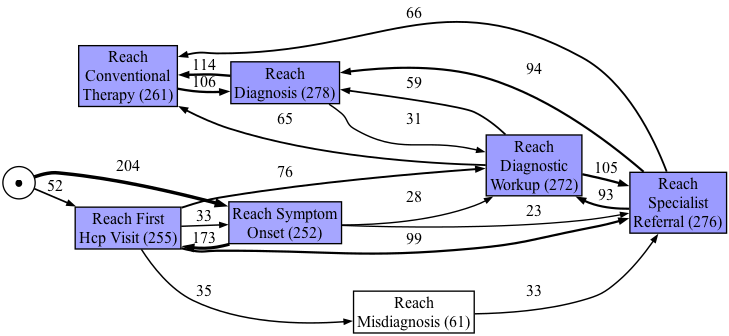

{'Figure': 'paper/figures/patient-journey-dfg.pdf',
 'Activities': 7,
 'Edges shown': 17}

,result,value,checked against
id,,,
CC.cases,Cases in the journey log flattened on Patient (PM4Py),280,Patient objects
CC.milestone_variants,Distinct milestone sequences (variants) in the case-centric log (PM4Py),204,"JSON file: milestone events per patient, by time then file order"
CC.milestone_activities,Milestone activities in the case-centric log (PM4Py),15,milestone types


In [29]:
# pm4py.ocel_flattening(ocel, "Patient") (section 3.1), prepared as a case-centric log with pm4py.format_dataframe.
# Without it, pm4py.get_variants does not sort the events of a case (PM4Py 2.7.23.12, pandas_numpy_variants.apply
# calls sort_values without using its result) and returns wrong variants.
CC_LOG = pm4py.format_dataframe(flat_patient.copy(), case_id="case:concept:name", activity_key="concept:name",
                                timestamp_key="time:timestamp")
assert CC_LOG["ocel:eid"].is_unique and len(CC_LOG) == len(J["events"])
report("CC.cases", "Cases in the journey log flattened on Patient (PM4Py)", CC_LOG["case:concept:name"].nunique(),
       {"Patient objects": n_patients})
CC_MS = CC_LOG[CC_LOG["concept:name"].str.startswith("Reach")]
assert len(CC_MS) == values()["RQ1.milestone_events"]

ms_variants = pm4py.get_variants(CC_MS)
seq_json = (EV[EV["kind"].eq("milestone")].sort_values(["patient", "time", "order"])
            .groupby("patient")["activity"].agg(tuple))
report("CC.milestone_variants", "Distinct milestone sequences (variants) in the case-centric log (PM4Py)", len(ms_variants),
       {"JSON file: milestone events per patient, by time then file order": seq_json.nunique()})
cc_dfg_all, _, _ = pm4py.discover_dfg(CC_MS)
assert len(cc_dfg_all) == values()["RQ2.R5.dfg_edges_Patient_milestones"], "PM4Py's milestone DFG differs from section 2.5"
report("CC.milestone_activities", "Milestone activities in the case-centric log (PM4Py)", CC_MS["concept:name"].nunique(),
       {"milestone types": values()["RQ2.R4.milestone_types"]})

# Times between milestones from the flattened log: they must equal section 4.
cc_time = CC_MS.pivot(index="case:concept:name", columns="concept:name", values="time:timestamp")
cc_gap = (cc_time["ReachDiagnosis"] - cc_time["ReachSymptomOnset"]).dropna().dt.days / DAYS_PER_MONTH
assert len(cc_gap) == values()["RQ4.symptom_onset_to_diagnosis_patients"]
assert round(cc_gap.median(), 1) == values()["RQ4.symptom_onset_to_diagnosis_median_months"]
assert round(cc_gap.quantile(0.25), 1) == values()["RQ4.symptom_onset_to_diagnosis_q1_months"]
assert round(cc_gap.quantile(0.75), 1) == values()["RQ4.symptom_onset_to_diagnosis_q3_months"]
cc_mis = cc_time["ReachMisdiagnosis"].reindex(cc_gap.index).notna()
assert round(cc_gap[cc_mis].median(), 1) == values()["RQ4.misdiagnosis_yes_median_months"]
assert round(cc_gap[~cc_mis].median(), 1) == values()["RQ4.misdiagnosis_no_median_months"]

# Figure: the path from symptom onset to the first conventional therapy.
CC_FIGURE_ACTIVITIES = ["ReachSymptomOnset", "ReachFirstHcpVisit", "ReachMisdiagnosis", "ReachSpecialistReferral",
                        "ReachDiagnosticWorkup", "ReachDiagnosis", "ReachConventionalTherapy"]
CC_PATHS_SHARE = 0.4
cc_fig_log = pm4py.filter_event_attribute_values(CC_MS, "concept:name", CC_FIGURE_ACTIVITIES, level="event")
cc_fig_log = cc_fig_log.assign(**{"concept:name": cc_fig_log["concept:name"].map(wrap)})
dfg, start_acts, end_acts = pm4py.discover_dfg(cc_fig_log)
act_count = cc_fig_log["concept:name"].value_counts().to_dict()
dfg, start_acts, end_acts, act_count = dfg_filtering.filter_dfg_on_paths_percentage(
    dfg, start_acts, end_acts, act_count, CC_PATHS_SHARE)
gviz = dfg_visualizer.apply(dfg, activities_count=act_count, variant=dfg_visualizer.Variants.FREQUENCY,
                            parameters={"format": "pdf", "start_activities": start_acts, "end_activities": {}, "rankdir": "LR"})
CC_FIGURE = PAPER / "figures" / "patient-journey-dfg.pdf"
gviz = paper_style(gviz)
gviz.body.append('\t{rank=source; "@@startnode"}\n')                # the start node on the left
save_figure(gviz, CC_FIGURE)
display({"Figure": str(CC_FIGURE), "Activities": len(act_count), "Edges shown": len(dfg)})
show("CC.")

### 6.4 Comorbidity, in PM4Py

A patient's journeys are `PatientCondition` objects, one per condition. For this analysis, a copy of the log splits them into two object types by their `condition_code`: **MG** (the journey of myasthenia gravis) and **Comorbidity** (the journey of any other condition). Nothing else changes. Both remain related to their **Patient**.

**Results.** First route: PM4Py's relations table. Second route: the JSON file (E2O relationships and the journeys' `condition_code`).

- patients with events in a comorbidity journey; comorbidity journeys with events; their events;
- the comorbidity diagnoses (`ReceiveDiagnosis` in a comorbidity journey) of patients with a dated MG diagnosis (`ReachDiagnosis`), and how many are dated before it, after it, or at the same time.

In a log with the patient as case, a diagnosis of myasthenia gravis and of asthma are the same activity, `ReceiveDiagnosis`. Only the journey object tells them apart.

In [30]:
MG = "conditions.myasthenia_gravis"
condition_of = {oid: OBJ_ATTR[oid].get("condition_code") for oid in OBJ.index[OBJ["type"].eq("PatientCondition")]}


def journey_type(oid, otype):
    if otype != "PatientCondition":
        return otype
    return "MG" if condition_of[oid] == MG else "Comorbidity"


oc_log = copy.deepcopy(ocel)
oc_log.objects["ocel:type"] = [journey_type(o, t) for o, t in zip(oc_log.objects["ocel:oid"], oc_log.objects["ocel:type"])]
oc_log.relations["ocel:type"] = [journey_type(o, t) for o, t in zip(oc_log.relations["ocel:oid"], oc_log.relations["ocel:type"])]

# Route 1: PM4Py's relations table.
rel = oc_log.relations
patient_of_event = rel[rel["ocel:type"].eq("Patient")].set_index("ocel:eid")["ocel:oid"].map(patient_of_id)
como = rel[rel["ocel:type"].eq("Comorbidity")]
como_dx = como[como["ocel:activity"].eq("ReceiveDiagnosis")].drop_duplicates("ocel:eid")
mg_dx_pm = rel[rel["ocel:activity"].eq("ReachDiagnosis") & rel["ocel:type"].eq("Patient")].set_index("ocel:oid")["ocel:timestamp"]
mg_dx_pm.index = mg_dx_pm.index.map(patient_of_id)
dx_time = como_dx["ocel:eid"].map(patient_of_event).map(mg_dx_pm)
dated = dx_time.notna()

# Route 2: the JSON file.
como_journeys = {oid for oid, c in condition_of.items() if c != MG}
e2o_como = E2O[E2O["object"].isin(como_journeys)].drop_duplicates(["event", "object"])
como_events_json = set(e2o_como["event"])
como_dx_json = EV.loc[sorted(como_events_json)].query("activity == 'ReceiveDiagnosis'")
mg_dx_json = EV[EV["activity"].eq("ReachDiagnosis")].set_index("patient")["time"]
dx_time_json = como_dx_json["patient"].map(mg_dx_json)
dated_json = dx_time_json.notna()

report("OC.patients_comorbidity", "Patients with events in a comorbidity journey (PM4Py)",
       como["ocel:eid"].map(patient_of_event).nunique(), {"JSON file": EV.loc[sorted(como_events_json), "patient"].nunique()})
report("OC.comorbidity_journeys", "Comorbidity journeys with events (PM4Py)", como["ocel:oid"].nunique(),
       {"JSON file": e2o_como["object"].nunique()})
report("OC.comorbidity_events", "Events in a comorbidity journey (PM4Py)", como["ocel:eid"].nunique(),
       {"JSON file": len(como_events_json)})
report("OC.comorbidity_diagnoses", "Comorbidity diagnoses (ReceiveDiagnosis in a comorbidity journey, PM4Py)", len(como_dx),
       {"JSON file": len(como_dx_json)})
report("OC.comorbidity_diagnoses_mg_dated", "Comorbidity diagnoses of patients with a dated MG diagnosis (PM4Py)",
       int(dated.sum()), {"JSON file": int(dated_json.sum())})
for key, label, op in [("before", "dated before", "lt"), ("after", "dated after", "gt"), ("same_time", "at the same time as", "eq")]:
    report(f"OC.comorbidity_diagnoses_{key}_mg", f"Comorbidity diagnoses {label} the MG diagnosis (PM4Py)",
           int(getattr(como_dx["ocel:timestamp"][dated], op)(dx_time[dated]).sum()),
           {"JSON file": int(getattr(como_dx_json["time"][dated_json], op)(dx_time_json[dated_json]).sum())})
show("OC.comorbidity")
show("OC.patients")


,result,value,checked against
id,,,
OC.comorbidity_journeys,Comorbidity journeys with events (PM4Py),362,JSON file
OC.comorbidity_events,Events in a comorbidity journey (PM4Py),741,JSON file
OC.comorbidity_diagnoses,"Comorbidity diagnoses (ReceiveDiagnosis in a comorbidity journey, PM4Py)",251,JSON file
OC.comorbidity_diagnoses_mg_dated,Comorbidity diagnoses of patients with a dated MG diagnosis (PM4Py),246,JSON file
OC.comorbidity_diagnoses_before_mg,Comorbidity diagnoses dated before the MG diagnosis (PM4Py),136,JSON file
OC.comorbidity_diagnoses_after_mg,Comorbidity diagnoses dated after the MG diagnosis (PM4Py),97,JSON file
OC.comorbidity_diagnoses_same_time_mg,Comorbidity diagnoses at the same time as the MG diagnosis (PM4Py),13,JSON file


,result,value,checked against
id,,,
OC.patients_comorbidity,Patients with events in a comorbidity journey (PM4Py),211,JSON file


### 6.5 Figure: journeys and treatment courses, object-centric, in PM4Py

The OC-DFG (`pm4py.discover_ocdfg`) of the journey log, restricted to three activities (`ReceiveDiagnosis`, `StartTreatment`, `EndTreatment`) and two of its object types: `PatientCondition` (a journey) and `TreatmentCourse`. Both are object types of the log as it is: nothing is renamed or split.

**What the figure shows without a label.** The two object types share the treatment activities, but not their paths:

- a course's path never goes from `EndTreatment` back to `StartTreatment`: after its end, a course stops;
- a journey's path does. In each of these pairs, the treatment that starts belongs to another course of the same journey: the figure shows treatment switches, though no activity is called *switch*;
- a journey starts with a diagnosis, a course with a treatment start; and many more journeys start than there are patients.

With the patient as case (PM4Py's DFG on the flattened log), the same edge `EndTreatment → StartTreatment` exists, but it cannot tell a switch from a restart or from a treatment of another condition.

**Results.** First route: PM4Py (the OC-DFG's own edge and start-activity counts; the DFG of the log flattened on `Patient`). Second route: the JSON file, each object's events of the three activities ordered by time and then by position in the file.

**Presentation only.** Edges below 40 event couples are hidden by PM4Py's visualiser. Edge labels keep the count; the object type is given by colour and, for `TreatmentCourse`, a dashed line. Start nodes are placed left, end markers right, and two backward edges do not drive the left-to-right order.

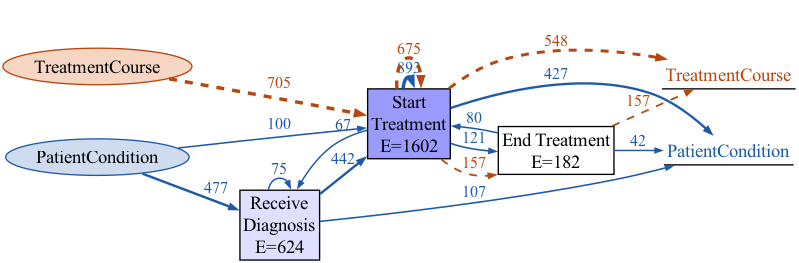

,result,value,checked against
id,,,
OC.patients_comorbidity,Patients with events in a comorbidity journey (PM4Py),211,JSON file
OC.comorbidity_journeys,Comorbidity journeys with events (PM4Py),362,JSON file
OC.comorbidity_events,Events in a comorbidity journey (PM4Py),741,JSON file
OC.comorbidity_diagnoses,"Comorbidity diagnoses (ReceiveDiagnosis in a comorbidity journey, PM4Py)",251,JSON file
OC.comorbidity_diagnoses_mg_dated,Comorbidity diagnoses of patients with a dated MG diagnosis (PM4Py),246,JSON file
OC.comorbidity_diagnoses_before_mg,Comorbidity diagnoses dated before the MG diagnosis (PM4Py),136,JSON file
OC.comorbidity_diagnoses_after_mg,Comorbidity diagnoses dated after the MG diagnosis (PM4Py),97,JSON file
OC.comorbidity_diagnoses_same_time_mg,Comorbidity diagnoses at the same time as the MG diagnosis (PM4Py),13,JSON file
OC.course_end_to_start,TreatmentCourse: EndTreatment -> StartTreatment pairs (PM4Py OC-DFG),0,JSON file


,result,value,checked against
id,,,
CC.patient_end_to_start,Patient as case: EndTreatment -> StartTreatment pairs (PM4Py DFG),114,JSON file


In [31]:
OC_ACTIVITIES = ["ReceiveDiagnosis", "StartTreatment", "EndTreatment"]
OC_TYPES = ["PatientCondition", "TreatmentCourse"]
END_START = ("EndTreatment", "StartTreatment")
oc_sub = pm4py.filter_ocel_object_types(pm4py.filter_ocel_event_attribute(ocel, "ocel:activity", OC_ACTIVITIES), OC_TYPES)
oc_dfg = pm4py.discover_ocdfg(oc_sub)
oc_ec = oc_dfg["edges"]["event_couples"]

# Route 1 for the course of each pair: PM4Py's relations of the sub-log, in PM4Py's order (time, then event order).
pm_order = pd.Series(range(len(oc_sub.events)), index=oc_sub.events["ocel:eid"])
pm_course = oc_sub.relations[oc_sub.relations["ocel:qualifier"].eq("in_course")].set_index("ocel:eid")["ocel:oid"]
pm_jr = (oc_sub.relations[oc_sub.relations["ocel:type"].eq("PatientCondition")].drop_duplicates(["ocel:eid", "ocel:oid"])
         .assign(o=lambda d: d["ocel:eid"].map(pm_order)).sort_values(["ocel:oid", "ocel:timestamp", "o"]))
pm_next = pm_jr.groupby("ocel:oid").shift(-1)
pm_es = pm_jr[pm_jr["ocel:activity"].eq(END_START[0]) & pm_next["ocel:activity"].eq(END_START[1])]
pm_es_next = pm_next.loc[pm_es.index, "ocel:eid"]


# Route 2: the JSON file.
def sequences(object_type, qualifiers):
    rel = E2O[E2O["qualifier"].isin(qualifiers) & E2O["object"].map(OBJ_TYPE).eq(object_type)].drop_duplicates(["event", "object"])
    rel = rel.join(EV[["activity", "time", "order"]], on="event")
    rel = rel[rel["activity"].isin(OC_ACTIVITIES)].sort_values(["object", "time", "order"])
    return {o: list(zip(g["event"], g["activity"])) for o, g in rel.groupby("object")}


def end_start_pairs(seqs):
    return [(o, a[0], b[0]) for o, s in seqs.items() for a, b in zip(s, s[1:]) if (a[1], b[1]) == END_START]


journey_seq = sequences("PatientCondition", QUALIFIERS["PatientCondition"])
course_seq = sequences("TreatmentCourse", QUALIFIERS["TreatmentCourse"])
course_of_event = E2O[E2O["qualifier"].eq("in_course")].set_index("event")["object"]
journey_pairs = end_start_pairs(journey_seq)

report("OC.course_end_to_start", "TreatmentCourse: EndTreatment -> StartTreatment pairs (PM4Py OC-DFG)",
       len(oc_ec["TreatmentCourse"].get(END_START, [])), {"JSON file": len(end_start_pairs(course_seq))})
report("OC.journey_end_to_start", "PatientCondition: EndTreatment -> StartTreatment pairs (PM4Py OC-DFG)",
       len(oc_ec["PatientCondition"].get(END_START, [])), {"JSON file": len(journey_pairs)})
report("OC.journeys_with_switch", "Journeys with an EndTreatment -> StartTreatment pair (PM4Py OC-DFG)",
       len(oc_dfg["edges"]["unique_objects"]["PatientCondition"].get(END_START, [])),
       {"JSON file": len({o for o, _, _ in journey_pairs})})
report("OC.switch_to_other_course", "Journey EndTreatment -> StartTreatment pairs whose start is in another course (PM4Py)",
       sum(1 for a, b in zip(pm_es["ocel:eid"], pm_es_next) if pm_course.get(a) is not None and pm_course.get(b) is not None
           and pm_course.get(a) != pm_course.get(b)),
       {"JSON file": sum(1 for _, a, b in journey_pairs if a in course_of_event.index and b in course_of_event.index
                         and course_of_event[a] != course_of_event[b])})
report("OC.journeys_start_with_diagnosis", "Journeys whose first event of the three is ReceiveDiagnosis (PM4Py OC-DFG)",
       len(oc_dfg["start_activities"]["events"]["PatientCondition"].get("ReceiveDiagnosis", [])),
       {"JSON file": sum(1 for s in journey_seq.values() if s[0][1] == "ReceiveDiagnosis")})
assert values()["OC.switch_to_other_course"] == values()["OC.journey_end_to_start"], "a journey switch within one course"

# With the patient as case: PM4Py's DFG on the flattened log, the same three activities.
cc_three = CC_LOG[CC_LOG["concept:name"].isin(OC_ACTIVITIES)]
cc_three_dfg, _, _ = pm4py.discover_dfg(cc_three)
patient_seq = sequences("Patient", QUALIFIERS["Patient"])
report("CC.patient_end_to_start", "Patient as case: EndTreatment -> StartTreatment pairs (PM4Py DFG)",
       cc_three_dfg.get(END_START, 0), {"JSON file": len(end_start_pairs(patient_seq))})

# Figure.
oc_fig = copy.deepcopy(oc_sub)
for table in (oc_fig.events, oc_fig.relations):
    table["ocel:activity"] = table["ocel:activity"].map(wrap)
gviz = ocdfg_visualizer.apply(pm4py.discover_ocdfg(oc_fig), parameters={"format": "pdf", "edge_threshold": 40, "rankdir": "LR"})
gviz = ocdfg_layout(fixed_colors(paper_style(gviz)), dashed_type="TreatmentCourse",
                    back_edges={("Start", "Receive"), ("End", "Start")})
OC_FIGURE = PAPER / "figures" / "journey-course-ocdfg.pdf"
save_figure(gviz, OC_FIGURE)
show("OC.")
show("CC.patient")

## 7. All results

Every result recorded by `report()`, in order, with the route it was checked against. The same table is written to `evaluation-results.json`, together with the input hashes and package versions. The file does not change between runs on the same inputs.

In [32]:
all_results = pd.DataFrame(RESULTS, dtype=object).set_index("id")
with pd.option_context("display.max_rows", None):
    display(all_results)

out = {
    "inputs": {name: {"file": path, "sha256": pinned} for name, (path, pinned) in INPUTS.items()},
    "environment": ENVIRONMENT,
    "results": RESULTS,
}
Path("evaluation-results.json").write_text(json.dumps(out, indent=1, ensure_ascii=False) + "\n")
print(f"{len(RESULTS)} results, each confirmed by a second route, written to evaluation-results.json")

,result,value,checked against
id,,,
RQ1.patients,Patients in the cohort log,280,build report: cohort patients; distinct patients of the journey events
RQ1.patients_left_out,"Exported patients left out whole (no journey summary, P10)",4,build report: patients with 'patient left out'
RQ1.patients_exported,Patients in the export,284,patients in the journey log plus patients labelled 'patient left out'
RQ1.events,Events in the journey log,10364,PM4Py import; build report
RQ1.fact_events,Fact events (activities other than Reach*),8364,events carrying reported_at (only fact events have it)
RQ1.milestone_events,Milestone events (Reach*),2000,build report: milestones minus milestones without event
RQ1.objects,Objects in the journey log,17706,build report
RQ1.event_types,Event types (activities),30,PM4Py: distinct activities; build report
RQ1.object_types,Object types,13,distinct types of the objects; build report


139 results, each confirmed by a second route, written to evaluation-results.json


### 7.1 Every number in the paper is a result

Each line of the paper's LaTeX that contains a number must end in a comment that names its result ids, for example `46.3\%% RQ1.facts_without_event_pct`. The check reads every number in the text of the line and requires it to equal the value of one of the ids named in its comment, formatted as in the paper (thousands as `{,}`, floats to one decimal). It also requires every id named to exist. Names that contain digits (M1–M5, R1–R6, RQ1–RQ3, OCEL 2.0, PM4Py, E2O, O2O, S01, S31) are not numbers. Files that do not exist are skipped: `paper/evaluation-section.tex` is not in the repository.

In [33]:
VALUE = values()
PAPER_FILES = ["evaluation-section.tex", "table-requirements.tex", "section3-by-construction.tex"]
NOT_NUMBERS = re.compile(r"\\(?:label|ref|input|cite|includegraphics)(?:\[[^\]]*\])?\{[^}]*\}|\b(?:RQ|M|R|S)\d+\b|OCEL~?\s?2\.0|PM4Py|\b[EO]2O\b|\\multicolumn\{\d+\}"
                         r"|\\(?:sub)*section\*?|\d+(?:\.\d+)?\s?(?:cm|pt|mm)\b")
NUMBER = re.compile(r"\d+(?:\{,\}\d{3})*(?:\.\d+)?")
RESULT_ID = re.compile(r"\b(?:RQ\d|CC|OC)\.[A-Za-z0-9_.]*[A-Za-z0-9_]")


def split_comment(line):
    m = re.search(r"(?<!\\)%", line)
    return (line, "") if m is None else (line[:m.start()], line[m.end():])


def formats(v):
    if isinstance(v, bool) or not isinstance(v, (int, float)):
        return {str(v)}
    if isinstance(v, int):
        return {str(v), f"{v:,}".replace(",", "{,}")}
    return {f"{v:.1f}"}


problems, checked = [], Counter()
for name in PAPER_FILES:
    path = PAPER / name
    if not path.is_file():
        print(f"skipped: {path} not found")
        continue
    for no, line in enumerate(path.read_text().splitlines(), 1):
        text, comment = split_comment(line)
        ids = RESULT_ID.findall(comment)
        for rid in ids:
            if rid not in VALUE:
                problems.append(f"{name}:{no}: unknown result id {rid}")
        allowed = set().union(*(formats(VALUE[r]) for r in ids if r in VALUE)) if ids else set()
        strings = [str(VALUE[r]) for r in ids if r in VALUE and isinstance(VALUE[r], str)]
        for s in strings:
            text = text.replace(s, " ")
        for n in NUMBER.findall(NOT_NUMBERS.sub(" ", text)):
            checked[name] += 1
            if n not in allowed:
                problems.append(f"{name}:{no}: {n} is not the value of {ids or 'any result (no id in the comment)'}")
display(dict(checked))
assert not problems, "\n".join(problems)
print(f"{sum(checked.values())} numbers in the paper, each the value of a result named on its line")

skipped: paper/evaluation-section.tex not found
skipped: paper/section3-by-construction.tex not found


{'table-requirements.tex': 21}

21 numbers in the paper, each the value of a result named on its line
